# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 13: Final Recognition Model

### Objective

This notebook trains the **final iris recognition model** on the real few-shot images **plus** the verified synthetic images, and finds the best model.

```text
real train/support images (K per identity)  +  accepted synthetic images (Notebooks 10 and 11)
        -> recognition network (ViT / Swin / ConvNeXt / EfficientNet) -> 256-d embedding
        -> ArcFace + Triplet + Center loss
        -> evaluation on REAL unseen people and on a second dataset, exactly as in Notebook 07
```

The notebook must:

1. Train on real + synthetic images of the **training** identities only.
2. Support the candidate backbones **ViT**, **Swin Transformer**, **ConvNeXt**, and **EfficientNetV2** (plus the two Notebook 07 backbones, so that like-for-like comparisons are possible).
3. Use the **ArcFace + Triplet + Center** loss (and the ArcFace-only loss as the like-for-like variant).
4. Evaluate with the **identical protocol** as Notebook 07: same functions, same seed, same 5-way episodes, real images only.
5. Compare with the Notebook 07 baselines, and select the **best recognition model** with the validation set only.

### Important boundary of this notebook

This notebook performs **final training and evaluation of the recognizer only**.

It does not generate or verify images (Notebooks 10 and 11) or run the full ablation and statistics studies (Notebooks 16 to 18). Validation and test identities, and the second dataset, stay **real** and are never used for training.

## 1. Research rationale

### 1.1 What is trained, and on what

| Data | Source | Used for |
|---|---|---|
| **Real** images | Notebook 06: `train / support` (K per identity) | Training |
| **Synthetic** images | Notebook 10, kept by Notebook 11 (`accepted`) | Training |
| Everything else | `train / query`, `val`, `test`, the second dataset | **Evaluation only** (never trained on) |

The synthetic images belong to the same identities as the real ones, so every training identity ends up with `K` real and up to `N - K` accepted synthetic images.

### 1.2 Backbones

| Name | Model | Input handling |
|---|---|---|
| `vit_b_16` | Vision Transformer | strip resized to 224 x 224 |
| `swin_t` | Swin Transformer (tiny) | strip resized to 224 x 224 |
| `convnext_tiny` | ConvNeXt (tiny) | native 64 x 512 |
| `efficientnet_v2_s` | EfficientNetV2 (small) | native 64 x 512 |
| `efficientnet_b0`, `resnet50` | Notebook 07 backbones | native 64 x 512 |

All start from ImageNet weights when they can be downloaded (stored in `pretrained_models/torch_hub`); if the download fails the notebook falls back to random initialisation, says so loudly, and records `pretrained_loaded`. The backbone output is mapped to a 256-d embedding (Linear + BatchNorm).

### 1.3 The loss

All three terms act on the embedding of each training image:

| Term | What it does |
|---|---|
| **ArcFace** | Classification of the training identities with an additive angular margin (same settings as Notebook 07) |
| **Triplet** | Batch-hard triplet loss on unit-length embeddings: same identity close, different identity far |
| **Center loss** | Pulls each embedding towards a learned center of its identity |

`L = w_arc * ArcFace + w_tri * Triplet + w_center * Center`. The loss variants are `arcface` (the **like-for-like variant**, identical to Notebook 07's loss), `arcface_triplet`, `arcface_center`, and `arcface_triplet_center` (the final loss from the plan).

### 1.4 Batches, and the curriculum

The triplet loss needs several images of the same identity in one batch, so every batch is **class-balanced**: `BATCH_CLASSES` identities with `IMAGES_PER_CLASS` images each (default 16 x 4 = 64). One epoch is one pass over the identities.

Within an identity, the batch mixes real and synthetic images by a **real fraction** (the share of real images):

- A **curriculum** starts at `START_REAL_FRACTION = 1.0` (real images only) and moves linearly to `FINAL_REAL_FRACTION = 0.5` over `CURRICULUM_EPOCHS`. This follows the proposal's mitigation for the risk "overfitting to synthetic data: mix real and synthetic data with curriculum learning".
- Because the share is fixed per identity, real images are **oversampled** (each identity has only a few real images against many synthetic ones), so the real domain is never drowned out.
- Identities with no accepted synthetic image use their real images only.

### 1.5 "Best recognition model"

The best model is chosen **only with the validation identities** (lowest validation EER, ties broken by validation Rank-1), **per shot**, among the runs of `BEST_SELECTION_DATA_VARIANT`. The test and second-dataset numbers are looked at afterwards and never influence the choice. The best checkpoints are copied to `checkpoints/final_recognition/best/`.

### 1.6 Fair comparisons

There are three kinds of reference, and they answer different questions:

| Reference | Question it answers | Caveat |
|---|---|---|
| **Notebook 07 baselines** (`real_only`, `real_traditional_aug`) | Is the final model better than the baselines? | Notebook 07 used random batches and a different epoch definition, so differences also include the sampler |
| **Same-code control** (add `"real_only"` to `DATA_VARIANTS`) | Does adding synthetic data help, with everything else identical? | Doubles the number of runs |
| **Loss variants** (`arcface` against `arcface_triplet_center`) | Do the triplet and center terms help? | Same data in both |

The synthetic images were made by a generator trained on appearance-transformed views of the real images, which is the same family of transformations as the traditional-augmentation baseline. A claim that synthetic data helps should therefore be made against **`real_traditional_aug`** (Notebook 07) as well as against real-only training.

### 1.7 Protocol and leakage rules

Identical to Notebooks 07 to 12. Training uses real `train / support` plus synthetic images of those same identities; `val` picks the best epoch; `test` and the second dataset are evaluated once, with the best-validation weights. Before every run the notebook asserts that no training image, class, or person appears in a validation, test, or cross-dataset set, and that every synthetic image is a `train` image of a training identity.

### 1.8 Things to keep in mind

- **Compute.** With ~20 images per identity the notebook sees up to 20 times more images than Notebook 7, but one epoch is only one pass over the identities, so an EfficientNet-B0 run is of the order of Notebook 07's. Heavier backbones cost far more; the log prints the time.
- **One seed** measures training randomness only; the support draw is fixed by Notebook 06.
- The synthetic images were accepted by a model trained on the same real images; the filter and the final model are therefore not independent.
- **Run `QUICK_TEST = True` first.** **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import hashlib
import json
import math
import random
import shutil
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
    from torchvision.transforms import functional as tv_F
except ImportError as error:
    raise ImportError(
        "Notebook 13 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

PRETRAINED_DIR = PROJECT_ROOT / "pretrained_models"
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

# ImageNet weights downloaded by torchvision are kept inside the project.
torch.hub.set_dir(str(PRETRAINED_DIR / "torch_hub"))

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)
print("Pretrained weights cache:", PRETRAINED_DIR / "torch_hub")

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset
Pretrained weights cache: E:\Research\LargeScale_Synthetic_Iris_Generation\pretrained_models\torch_hub


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished run is skipped on re-run only if its stored fingerprint matches, so changing a hyperparameter can never silently reuse stale results.

- `QUICK_TEST = True` shrinks the experiment (one backbone, 3 epochs, 60 classes) to check the whole pipeline. It reads the **quick-test outputs of Notebooks 07, 10 and 11** and writes to separate folders.
- `DATA_VARIANTS`: `"real_plus_synthetic"` is the proposed model. Add `"real_only"` to also train the **same-code control** (identical pipeline, no synthetic images).
- `LOSS_VARIANTS`: any of `"arcface"`, `"arcface_triplet"`, `"arcface_center"`, `"arcface_triplet_center"`.
- `SYNTHETIC_SOURCE`: `"accepted"` (Notebook 11's accepted images, the default) or `"all"` (every generated image, unfiltered). `SYNTHETIC_PER_IDENTITY` keeps only the first `m` synthetic images (by their index) per identity, for nested subsets; `None` keeps all.
- `START_REAL_FRACTION`, `FINAL_REAL_FRACTION`, `CURRICULUM_EPOCHS` define the curriculum of section 1.4; `CURRICULUM_EPOCHS = 0` uses the final fraction from the start.
- `TRADITIONAL_AUG = True` additionally applies Notebook 07's augmentation to every training image (off by default, so the proposed model stays distinct from the traditional-augmentation baseline).
- `W_*` are the loss weights; `CENTER_LR` is the learning rate of the identity centers.
- `SELECTION_METRIC` decides which validation metric picks the best epoch.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = tiny smoke test, written to separate folders

# ---- what to run ----
SHOTS_TO_RUN = [1, 2, 3, 5]
BACKBONES = ["efficientnet_b0"]     # also: "efficientnet_v2_s", "convnext_tiny", "swin_t", "vit_b_16", "resnet50"
DATA_VARIANTS = ["real_plus_synthetic"]     # add "real_only" for the same-code control
LOSS_VARIANTS = ["arcface", "arcface_triplet_center"]
SEEDS = [42]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]

# ---- synthetic data (Notebooks 10 and 11) ----
SYNTHETIC_SOURCE = "all"       # "accepted" (Notebook 11) or "all" (Notebook 10, unfiltered)
GENERATOR_SEED = 42                 # the Notebook 09 / 10 run: diffusion__<K>shot__seed<GENERATOR_SEED>
SYNTHETIC_PER_IDENTITY = None       # e.g. 5, 10, 20: keep only the first m synthetic images per identity
UPSTREAM_FROM_QUICKTEST = QUICK_TEST

# ---- model ----
USE_PRETRAINED = True               # ImageNet initialisation (falls back loudly if unavailable)
EMBEDDING_DIM = 256
INPUT_HW = (64, 512)                # size of the normalized iris textures from Notebook 03
SQUARE_INPUT_SIZE = 224             # ViT and Swin need a square input
KNOWN_BACKBONES = {                 # name -> (feature size, needs a square input)
    "resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_v2_s": (1280, False),
    "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True),
}

# ---- loss ----
ARC_SCALE = 30.0
ARC_MARGIN = 0.5
TRIPLET_MARGIN = 0.3
W_ARCFACE = 1.0
W_TRIPLET = 1.0
W_CENTER = 0.1
CENTER_LR = 0.05

# ---- batches (class-balanced) and curriculum ----
BATCH_CLASSES = 16                  # identities per batch
IMAGES_PER_CLASS = 4                # images per identity per batch (batch size = product)
START_REAL_FRACTION = 1.0           # share of real images at the start of training
FINAL_REAL_FRACTION = 0.5           # share of real images after the curriculum
CURRICULUM_EPOCHS = 10
TRADITIONAL_AUG = False

# ---- optimisation ----
EPOCHS = 60                         # one epoch = one pass over the training identities
BASE_LR_PRETRAINED = {"resnet50": 1e-4, "efficientnet_b0": 3e-4, "efficientnet_v2_s": 3e-4,
                      "convnext_tiny": 1e-4, "swin_t": 5e-5, "vit_b_16": 3e-5}
BASE_LR_SCRATCH = 1e-3
HEAD_LR_MULT = 10.0                 # embedding layer and ArcFace weights learn faster than the backbone
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 1
GRAD_CLIP = 5.0
MIXED_PRECISION = True              # used only on CUDA

# ---- model selection (validation identities only) ----
EVAL_EVERY = 2
EARLY_STOP_PATIENCE = 8
SELECTION_METRIC = "eer"            # "eer" (lower is better) or "rank1" (higher is better)

# ---- traditional augmentation (only when TRADITIONAL_AUG is True; same values as Notebook 07) ----
AUG_MAX_SHIFT = 32
AUG_BRIGHTNESS = 0.2
AUG_CONTRAST = 0.2
AUG_BLUR_PROB = 0.3
AUG_NOISE_PROB = 0.3
AUG_NOISE_STD = 0.04
AUG_HFLIP_PROB = 0.0

# ---- evaluation (identical to Notebook 07) ----
EVAL_SEED = 2024
EPISODE_WAY = 5
NUM_EPISODES = 600
MAX_IMPOSTOR_SCORES = 5_000_000
FAR_TARGETS = [1e-2, 1e-3]
CROSS_DATASET_USE_ALL_SPLITS = True
EVALUATE_TRAIN_CLOSED_SET = True

# ---- bookkeeping ----
MAX_TRAIN_CLASSES = None
RESUME = True
SAVE_CHECKPOINTS = True
BEST_SELECTION_DATA_VARIANT = "real_plus_synthetic"     # which runs compete for "best recognition model"

if QUICK_TEST:
    SHOTS_TO_RUN = [1, 3]
    BACKBONES = ["resnet50"]            # the backbone Notebook 07's quick test trains
    DATA_VARIANTS = ["real_plus_synthetic"]
    LOSS_VARIANTS = ["arcface", "arcface_triplet_center"]
    EPOCHS = 3
    EVAL_EVERY = 1
    CURRICULUM_EPOCHS = 1
    MAX_TRAIN_CLASSES = 60
    NUM_EPISODES = 100
    print("QUICK_TEST is ON: tiny experiment, separate output folders, reads the quick-test outputs of Notebooks 07, 10, 11.")

# ---- sanity checks on the configuration itself ----
for name in BACKBONES:
    assert name in KNOWN_BACKBONES, f"Unknown backbone '{name}'. Choose from {sorted(KNOWN_BACKBONES)}"
for name in DATA_VARIANTS:
    assert name in {"real_plus_synthetic", "real_only"}, f"Unknown data variant '{name}'"
for name in LOSS_VARIANTS:
    assert name in {"arcface", "arcface_triplet", "arcface_center", "arcface_triplet_center"}, f"Unknown loss variant '{name}'"
assert SYNTHETIC_SOURCE in {"accepted", "all"}, "SYNTHETIC_SOURCE must be 'accepted' or 'all'"
assert SELECTION_METRIC in {"eer", "rank1"}, "SELECTION_METRIC must be 'eer' or 'rank1'"
assert tuple(INPUT_HW) == (64, 512), "This notebook assumes 64 x 512 iris strips"
assert IMAGES_PER_CLASS >= 2 and BATCH_CLASSES >= 2, "triplet loss needs at least 2 images per identity and 2 identities per batch"
assert 0.0 < FINAL_REAL_FRACTION <= 1.0 and 0.0 < START_REAL_FRACTION <= 1.0, "real fractions must be in (0, 1]"
assert SYNTHETIC_PER_IDENTITY is None or SYNTHETIC_PER_IDENTITY >= 1
assert BEST_SELECTION_DATA_VARIANT in DATA_VARIANTS, "BEST_SELECTION_DATA_VARIANT must be one of DATA_VARIANTS"
assert len(SEEDS) >= 1 and len(SHOTS_TO_RUN) >= 1 and len(BACKBONES) >= 1 and len(DATA_VARIANTS) >= 1 and len(LOSS_VARIANTS) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Backbones:", BACKBONES, "| data:", DATA_VARIANTS, "| losses:", LOSS_VARIANTS, "| shots:", SHOTS_TO_RUN, "| seeds:", SEEDS)
print("Device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no CUDA GPU found. Full runs will be very slow on CPU; consider QUICK_TEST = True first.")

Backbones: ['efficientnet_b0'] | data: ['real_plus_synthetic'] | losses: ['arcface', 'arcface_triplet_center'] | shots: [1, 2, 3, 5] | seeds: [42]
Device: cuda | mixed precision: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
SYNTHETIC_DIR = PROJECT_ROOT / f"generated_images{upstream_suffix}"
SYNTHETIC_MANIFEST_PATH = PROJECT_ROOT / "results" / f"synthetic_generation{upstream_suffix}" / "synthetic_manifest.csv"
ACCEPTED_MANIFEST_PATH = PROJECT_ROOT / "results" / f"identity_verification{upstream_suffix}" / "accepted_manifest.csv"
BASELINE_SUMMARY_PATH = PROJECT_ROOT / "results" / f"baseline_recognition{upstream_suffix}" / "baseline_summary.csv"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"final_recognition{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"final_recognition{suffix}"
BEST_DIR = CHECKPOINT_DIR / "best"

for directory in [RESULTS_DIR, RUNS_DIR, CHECKPOINT_DIR, BEST_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 13 results:", RESULTS_DIR)
print("Checkpoints:", CHECKPOINT_DIR)
print("Best models:", BEST_DIR)

Notebook 13 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition
Checkpoints: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\final_recognition
Best models: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\final_recognition\best


## 5. Utility functions

Real images are read once, cached as `uint8`, and batched manually (no `DataLoader` worker processes), which avoids the multiprocessing problems Jupyter has on Windows. Synthetic images are never resized: a wrong-size file stops the notebook, because Notebook 10 guarantees the size.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def safe_name(text):
    return str(text).replace("/", "__").replace(" ", "_")


def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def make_generator_run_id(shot):
    return f"diffusion__{shot}shot__seed{GENERATOR_SEED}"


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def read_synthetic(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != tuple(INPUT_HW):
        raise ValueError(f"Synthetic image is missing, unreadable, or not {INPUT_HW}: {path}")
    return image

## 6. Load the datasets and check the upstream outputs

- `fewshot_manifest_long.csv` (Notebook 06) provides the **real** images and the splits.
- The synthetic manifest (Notebook 11's `accepted_manifest.csv`, or Notebook 10's `synthetic_manifest.csv` when `SYNTHETIC_SOURCE = "all"`) lists the synthetic images. Every image gets a **`verify_id`** built exactly as in Notebooks 11 and 12 (run, identity, index), so IDs are unique across shots.

Before anything starts, the notebook checks that every synthetic file exists (on a sample), that all synthetic images are marked as training images of training identities, and that no synthetic identity shares a person with another split. A shot without synthetic images is skipped for `real_plus_synthetic` with a warning.

In [6]:
# ============================================================
# 6. Load the datasets
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {
    "shot", "image_id", "dataset", "class_id", "subject_key",
    "split", "role", "relative_path", "source_path",
}

missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
available_shots = sorted(long_manifest["shot"].unique())

for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, (
        f"TRAIN_DATASETS contains '{dataset_name}', which is not in the manifest {available_datasets}")

shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot was requested but does not exist in the manifest; skipping it.")
if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the manifest.")

# ---- synthetic images ----
uses_synthetic = "real_plus_synthetic" in DATA_VARIANTS
synthetic_manifest = None
synthetic_shots = set()

if uses_synthetic:
    source_path = ACCEPTED_MANIFEST_PATH if SYNTHETIC_SOURCE == "accepted" else SYNTHETIC_MANIFEST_PATH
    if not source_path.exists():
        hint = ("11_Identity_Verification.ipynb (or set SYNTHETIC_SOURCE = 'all' to use every generated image unfiltered)"
                if SYNTHETIC_SOURCE == "accepted" else "10_Synthetic_Image_Generation.ipynb (run it to the end)")
        raise FileNotFoundError(f"Missing: {source_path}\nRun {hint} first.")

    def add_verify_id(table):
        '''Unique image ID built exactly as in Notebooks 11 and 12 (run, identity, index).'''
        if len(table) == 0:
            table["verify_id"] = pd.Series(dtype=object)
            return table
        table["verify_id"] = (table["generator_run_id"] + "|" + table["class_id"]
                              + "|syn_" + table["synth_index"].astype(int).map("{:03d}".format))
        return table

    synthetic_manifest = pd.read_csv(source_path, dtype={"identity": str, "eye": str})
    required_synthetic = {"class_id", "dataset", "subject_key", "shot", "synth_index", "relative_path", "generator_run_id"}
    missing = required_synthetic.difference(synthetic_manifest.columns)
    if missing:
        raise ValueError(f"The synthetic manifest is missing required columns: {sorted(missing)}")

    synthetic_manifest = add_verify_id(synthetic_manifest)

    if "split" not in synthetic_manifest.columns:
        # Notebook 11's accepted manifest does not carry the split, so it is taken from Notebook 10's manifest
        if not SYNTHETIC_MANIFEST_PATH.exists():
            raise FileNotFoundError(f"Missing: {SYNTHETIC_MANIFEST_PATH}\nRun 10_Synthetic_Image_Generation.ipynb first.")
        original = add_verify_id(pd.read_csv(SYNTHETIC_MANIFEST_PATH, dtype={"identity": str, "eye": str}))
        split_of = dict(zip(original["verify_id"], original["split"]))
        unknown = [v for v in synthetic_manifest["verify_id"] if v not in split_of]
        assert not unknown, f"{len(unknown)} accepted images are not in Notebook 10's manifest (a different run?)"
        synthetic_manifest["split"] = synthetic_manifest["verify_id"].map(split_of)

    assert synthetic_manifest["verify_id"].is_unique, "verify_id is not unique: the synthetic manifest repeats an image"

    synthetic_shots = {int(s) for s in synthetic_manifest["shot"].unique()
                       if bool(((synthetic_manifest["shot"] == s)
                                & (synthetic_manifest["generator_run_id"] == make_generator_run_id(int(s)))).any())}

    for shot in shots_to_run:
        if shot not in synthetic_shots:
            print(f"WARNING: no synthetic images for {shot}-shot (generator run {make_generator_run_id(shot)}); "
                  f"'real_plus_synthetic' is skipped for this shot.")

    # leakage guards and file checks
    for shot in [s for s in shots_to_run if s in synthetic_shots]:
        rows = synthetic_manifest[(synthetic_manifest["shot"] == shot)
                                  & (synthetic_manifest["generator_run_id"] == make_generator_run_id(shot))]
        real = long_manifest[long_manifest["shot"] == shot]
        train_support = real[(real["split"] == "train") & (real["role"] == "support") & (real["dataset"].isin(TRAIN_DATASETS))]
        assert (rows["split"] == "train").all(), f"{shot}-shot: a synthetic image is not labelled as a training image"
        assert set(rows["class_id"]) <= set(train_support["class_id"]), f"{shot}-shot: a synthetic identity is not a training identity"
        held_out = set(real.loc[~real["class_id"].isin(set(train_support["class_id"])), "subject_key"])
        assert not (set(rows["subject_key"]) & held_out), f"{shot}-shot: a synthetic identity shares a person with another split"
        absent = [p for p in rows["relative_path"].head(2000) if not (SYNTHETIC_DIR / p).exists()]
        assert not absent, f"{shot}-shot: {len(absent)} synthetic images are missing from {SYNTHETIC_DIR} (checked a sample)"

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)

overview = []
for shot in shots_to_run:
    real_rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["split"] == "train")
                              & (long_manifest["role"] == "support") & (long_manifest["dataset"].isin(TRAIN_DATASETS))]
    row = {"shot": shot, "train_identities": real_rows["class_id"].nunique(), "real_images": len(real_rows)}
    if synthetic_manifest is not None and shot in synthetic_shots:
        syn = synthetic_manifest[(synthetic_manifest["shot"] == shot)
                                 & (synthetic_manifest["generator_run_id"] == make_generator_run_id(shot))]
        syn = syn[syn["class_id"].isin(set(real_rows["class_id"]))]
        row.update({"synthetic_images": len(syn), "identities_with_synthetic": syn["class_id"].nunique()})
    overview.append(row)
display(pd.DataFrame(overview))

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "use_pretrained": USE_PRETRAINED, "embedding_dim": EMBEDDING_DIM,
    "input_hw": list(INPUT_HW), "square_input": SQUARE_INPUT_SIZE,
    "synthetic": [SYNTHETIC_SOURCE, GENERATOR_SEED, SYNTHETIC_PER_IDENTITY, UPSTREAM_FROM_QUICKTEST],
    "loss": [ARC_SCALE, ARC_MARGIN, TRIPLET_MARGIN, W_ARCFACE, W_TRIPLET, W_CENTER, CENTER_LR],
    "batches": [BATCH_CLASSES, IMAGES_PER_CLASS, START_REAL_FRACTION, FINAL_REAL_FRACTION, CURRICULUM_EPOCHS, TRADITIONAL_AUG],
    "optim": [EPOCHS, BASE_LR_PRETRAINED, BASE_LR_SCRATCH, HEAD_LR_MULT, WEIGHT_DECAY, WARMUP_EPOCHS, GRAD_CLIP],
    "selection": [EVAL_EVERY, EARLY_STOP_PATIENCE, SELECTION_METRIC],
    "aug": [AUG_MAX_SHIFT, AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_NOISE_STD, AUG_HFLIP_PROB],
    "eval": [EVAL_SEED, EPISODE_WAY, NUM_EPISODES, MAX_IMPOSTOR_SCORES, FAR_TARGETS,
             CROSS_DATASET_USE_ALL_SPLITS, EVALUATE_TRAIN_CLOSED_SET],
    "max_train_classes": MAX_TRAIN_CLASSES,
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
    "synthetic_digest": file_digest(source_path) if uses_synthetic else None,
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 2, 3, 5]


,shot,train_identities,real_images,synthetic_images,identities_with_synthetic
0,1,1390,1390,26410,1390
1,2,1384,2768,24912,1384
2,3,1369,4107,23273,1369
3,5,1294,6470,19410,1294


Configuration fingerprint: 78720afb11d1


## 7. Training data and evaluation sets

**Training data** for shot `K` (`build_training_data`):

- **real**: `split == train`, `role == support`, `dataset in TRAIN_DATASETS`;
- **synthetic** (only for `real_plus_synthetic`): the images of the synthetic manifest that belong to those same identities, ordered by identity and index, optionally cut to the first `SYNTHETIC_PER_IDENTITY` per identity.

All images are held in one `uint8` tensor (real first), with per-identity index lists for real and synthetic images that the batch sampler uses.

**Evaluation sets** are exactly those of Notebook 07 (all real, gallery = `support` rows, probes = `query` rows):

| Name | Data | Purpose |
|---|---|---|
| `<train dataset>/val` | unseen people | Picks the best epoch. Never reported as a result. |
| `<train dataset>/test` | unseen people | **Headline within-dataset result.** Evaluated once per run. |
| `<train dataset>/train_closed` | training people, held-out query images | Diagnostic only. |
| `<other dataset>/cross_dataset` | a dataset never seen in training | **Headline cross-dataset result.** |

Before every training run the notebook asserts that no training image (real or synthetic), class, or person appears in a validation, test, or cross-dataset set.

In [7]:
# ============================================================
# 7. Training data and evaluation sets
# ============================================================

def build_eval_set_specs():
    specs = []

    for dataset_name in available_datasets:
        if dataset_name in TRAIN_DATASETS:
            specs.append({"name": f"{dataset_name}/val", "dataset": dataset_name,
                          "splits": ["val"], "kind": "selection"})
            specs.append({"name": f"{dataset_name}/test", "dataset": dataset_name,
                          "splits": ["test"], "kind": "within_dataset_test"})
            if EVALUATE_TRAIN_CLOSED_SET:
                specs.append({"name": f"{dataset_name}/train_closed", "dataset": dataset_name,
                              "splits": ["train"], "kind": "train_closed_set_diagnostic"})
        else:
            splits = ["train", "val", "test"] if CROSS_DATASET_USE_ALL_SPLITS else ["test"]
            specs.append({"name": f"{dataset_name}/cross_dataset", "dataset": dataset_name,
                          "splits": splits, "kind": "cross_dataset"})

    return specs


EVAL_SET_SPECS = build_eval_set_specs()


def get_training_set(shot):
    '''The real training images: train / support of TRAIN_DATASETS.'''
    train_df = long_manifest[
        (long_manifest["shot"] == shot)
        & (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ].copy()

    if MAX_TRAIN_CLASSES is not None:
        # Deterministic subset that does not depend on the shot or the seed.
        ordered = sorted(train_df["class_id"].unique(), key=lambda c: (zlib.crc32(c.encode("utf-8")), c))
        keep = set(ordered[:MAX_TRAIN_CLASSES])
        train_df = train_df[train_df["class_id"].isin(keep)].copy()

    sort_columns = ["class_id", "shuffle_rank"] if "shuffle_rank" in train_df.columns else ["class_id", "image_id"]
    return train_df.sort_values(sort_columns).reset_index(drop=True)


def synthetic_rows_for(shot, class_names):
    '''The synthetic images of the given identities, ordered by identity and index.'''
    rows = synthetic_manifest[(synthetic_manifest["shot"] == shot)
                              & (synthetic_manifest["generator_run_id"] == make_generator_run_id(shot))]
    rows = rows[rows["class_id"].isin(set(class_names))].sort_values(["class_id", "synth_index"])

    if SYNTHETIC_PER_IDENTITY is not None:
        rows = rows.groupby("class_id").head(SYNTHETIC_PER_IDENTITY)

    return rows.reset_index(drop=True)


def build_training_data(shot, data_variant):
    '''All training images in one uint8 tensor (real first) with per-identity real / synthetic index lists.'''
    real_df = get_training_set(shot)
    class_names = sorted(real_df["class_id"].unique())
    class_to_index = {c: i for i, c in enumerate(class_names)}

    synthetic_df = synthetic_rows_for(shot, class_names) if data_variant == "real_plus_synthetic" else None
    n_real = len(real_df)
    n_synthetic = 0 if synthetic_df is None else len(synthetic_df)

    images = torch.empty((n_real + n_synthetic, *INPUT_HW), dtype=torch.uint8)
    images[:n_real] = load_image_tensor(real_df)
    labels = np.empty(n_real + n_synthetic, dtype=np.int64)
    labels[:n_real] = [class_to_index[c] for c in real_df["class_id"]]

    if n_synthetic:
        for k, row in enumerate(synthetic_df.itertuples(index=False)):
            images[n_real + k] = torch.from_numpy(read_synthetic(SYNTHETIC_DIR / row.relative_path))
        labels[n_real:] = [class_to_index[c] for c in synthetic_df["class_id"]]

    real_index = [np.flatnonzero(labels[:n_real] == c) for c in range(len(class_names))]
    synthetic_index = [n_real + np.flatnonzero(labels[n_real:] == c) for c in range(len(class_names))]

    leakage_df = real_df[["image_id", "class_id", "subject_key"]].copy()
    if n_synthetic:
        # built column by column, so it works whether or not the synthetic manifest already has an image_id column
        synthetic_leakage = pd.DataFrame({"image_id": synthetic_df["verify_id"].to_numpy(),
                                          "class_id": synthetic_df["class_id"].to_numpy(),
                                          "subject_key": synthetic_df["subject_key"].to_numpy()})
        leakage_df = pd.concat([leakage_df, synthetic_leakage], ignore_index=True)
        
    return {"images": images, "labels": labels, "class_names": class_names, "real_index": real_index,
            "synthetic_index": synthetic_index, "n_real": int(n_real), "n_synthetic": int(n_synthetic),
            "classes_without_synthetic": int(sum(len(s) == 0 for s in synthetic_index)), "leakage_df": leakage_df}


def get_eval_pool_defs(shot):
    '''Gallery (support) and probe (query) rows for every evaluation set at this shot.'''
    pool_defs = {}

    for spec in EVAL_SET_SPECS:
        rows = long_manifest[
            (long_manifest["shot"] == shot)
            & (long_manifest["dataset"] == spec["dataset"])
            & (long_manifest["split"].isin(spec["splits"]))
        ]
        support = rows[rows["role"] == "support"]
        query = rows[rows["role"] == "query"]

        if len(support) == 0 or len(query) == 0:
            continue

        pool_defs[spec["name"]] = {"spec": spec, "support_df": support, "query_df": query}

    return pool_defs


def materialize_pool(pool_def):
    support, query = pool_def["support_df"], pool_def["query_df"]
    return {
        "support_images": load_image_tensor(support),
        "support_labels": support["class_id"].to_numpy(),
        "query_images": load_image_tensor(query),
        "query_labels": query["class_id"].to_numpy(),
    }


def assert_no_leakage(train_df, pool_defs):
    '''Raise if any training image (real or synthetic), class, or person is also used for evaluation.'''
    train_images = set(train_df["image_id"])
    train_classes = set(train_df["class_id"])
    train_subjects = set(train_df["subject_key"])

    for name, pool_def in pool_defs.items():
        kind = pool_def["spec"]["kind"]
        query_images = set(pool_def["query_df"]["image_id"])

        # Probes must never be training images, for every kind of evaluation set.
        assert not (train_images & query_images), f"{name}: a probe image was used for training"

        if kind == "train_closed_set_diagnostic":
            continue  # same people on purpose; only the image-level rule above applies

        eval_df = pd.concat([pool_def["support_df"], pool_def["query_df"]])
        assert not (train_images & set(eval_df["image_id"])), f"{name}: shares images with the training set"
        assert not (train_classes & set(eval_df["class_id"])), f"{name}: shares classes with the training set"
        assert not (train_subjects & set(eval_df["subject_key"])), f"{name}: shares people with the training set"

    return True


print("Evaluation sets:")
display(pd.DataFrame(EVAL_SET_SPECS))

Evaluation sets:


,name,dataset,splits,kind
0,CASIA-Iris-Thousand/val,CASIA-Iris-Thousand,[val],selection
1,CASIA-Iris-Thousand/test,CASIA-Iris-Thousand,[test],within_dataset_test
2,CASIA-Iris-Thousand/train_closed,CASIA-Iris-Thousand,[train],train_closed_set_diagnostic
3,IITD/cross_dataset,IITD,"[train, val, test]",cross_dataset


## 8. Evaluation metrics

These are **the same functions as in Notebook 07** (with the matrix multiplication done by `np.einsum`, which avoids the library that crashed the kernel on some Windows installs). Scoring the final model with exactly this code, the same `EVAL_SEED`, and the same evaluation sets is what makes the comparison with the baselines fair: prototypes from the `K` support images, probes from the query images, cosine similarity, the same 5-way episodes.

The next cell verifies the functions against brute-force calculations.

In [8]:
# ============================================================
# 8. Evaluation metrics (same protocol as Notebook 07)
# ============================================================

FPR_GRID = np.unique(np.concatenate([[0.0], np.logspace(-5, 0, 151), np.linspace(0.0, 1.0, 101)]))


def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


def compute_roc(genuine, impostor):
    '''ROC points over every distinct score. Returns (fpr, tpr), both starting at (0, 0).'''
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])

    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]

    true_pos = np.cumsum(labels)
    false_pos = np.cumsum(1.0 - labels)

    # keep only the last point of each run of tied scores
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])

    tpr = np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)])
    fpr = np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)])
    return fpr, tpr


def auc_from_roc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def eer_from_roc(fpr, tpr):
    fnr = 1.0 - tpr
    difference = fpr - fnr   # non-decreasing: starts at -1, ends at +1
    index = int(np.searchsorted(difference, 0.0, side="left"))

    if index <= 0:
        return float(fpr[0])
    if index >= len(difference):
        return float(fpr[-1])

    d0, d1 = difference[index - 1], difference[index]
    fraction = 0.0 if d1 == d0 else (0.0 - d0) / (d1 - d0)
    return float(fpr[index - 1] + fraction * (fpr[index] - fpr[index - 1]))


def tpr_at_fpr(fpr, tpr, target):
    '''Highest TPR whose FPR is at most target.'''
    index = int(np.searchsorted(fpr, target, side="right")) - 1
    return float(tpr[max(index, 0)])


def evaluate_embeddings(support_emb, support_labels, query_emb, query_labels, seed_label):
    '''Score one evaluation set.

    support_emb / query_emb are L2-normalised embeddings. Gallery = one prototype per class
    (mean of its support embeddings); probes = query embeddings; score = cosine similarity.'''

    classes, class_index = np.unique(support_labels, return_inverse=True)
    n_classes = len(classes)

    prototypes = np.zeros((n_classes, support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no gallery images")

    query_index = np.array([lookup[label] for label in query_labels])

    # np.einsum is used instead of the "@" operator on purpose: it never calls the BLAS / OpenMP
    # libraries, which can crash the Jupyter kernel on some Windows installs.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    n_query = len(query_index)

    predicted = similarity.argmax(axis=1)
    correct = predicted == query_index
    metrics = {
        "n_classes": int(n_classes),
        "n_support": int(len(support_labels)),
        "n_query": int(n_query),
        "chance_rank1": float(1.0 / n_classes),
        "rank1_acc": float(correct.mean()),
    }

    # macro F1 over classes that have probes
    true_count = np.bincount(query_index, minlength=n_classes)
    pred_count = np.bincount(predicted, minlength=n_classes)
    tp = np.bincount(query_index[correct], minlength=n_classes)
    precision = np.divide(tp, pred_count, out=np.zeros(n_classes), where=pred_count > 0)
    recall = np.divide(tp, true_count, out=np.zeros(n_classes), where=true_count > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(n_classes), where=(precision + recall) > 0)
    metrics["f1_macro"] = float(f1[true_count > 0].mean())

    # N-way episodes (fixed seed -> identical episodes for every model)
    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(str(seed_label).encode("utf-8"))])

    if n_classes >= EPISODE_WAY:
        episode_acc = np.empty(NUM_EPISODES)
        for e in range(NUM_EPISODES):
            chosen = rng.choice(n_classes, EPISODE_WAY, replace=False)
            rows = np.flatnonzero(np.isin(query_index, chosen))
            sub = similarity[np.ix_(rows, chosen)]
            episode_acc[e] = (chosen[sub.argmax(axis=1)] == query_index[rows]).mean()
        metrics["acc_5way"] = float(episode_acc.mean())
        metrics["acc_5way_ci95"] = float(1.96 * episode_acc.std(ddof=1) / math.sqrt(NUM_EPISODES))
    else:
        metrics["acc_5way"] = float("nan")
        metrics["acc_5way_ci95"] = float("nan")

    # verification: genuine = probe vs own prototype, impostor = probe vs every other prototype
    genuine = similarity[np.arange(n_query), query_index]
    impostor_mask = np.ones_like(similarity, dtype=bool)
    impostor_mask[np.arange(n_query), query_index] = False
    impostor = similarity[impostor_mask]

    if len(impostor) > MAX_IMPOSTOR_SCORES:
        impostor = rng.choice(impostor, MAX_IMPOSTOR_SCORES, replace=False)

    metrics["n_genuine"] = int(len(genuine))
    metrics["n_impostor"] = int(len(impostor))

    if len(genuine) == 0 or len(impostor) == 0:
        metrics.update({"roc_auc": float("nan"), "eer": float("nan")})
        for far in FAR_TARGETS:
            metrics[tar_key(far)] = float("nan")
        return metrics, np.full(len(FPR_GRID), np.nan)

    fpr, tpr = compute_roc(genuine, impostor)
    metrics["roc_auc"] = auc_from_roc(fpr, tpr)
    metrics["eer"] = eer_from_roc(fpr, tpr)

    for far in FAR_TARGETS:
        resolvable = len(impostor) * far >= 1.0
        metrics[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if resolvable else float("nan")

    tpr_on_grid = np.array([tpr_at_fpr(fpr, tpr, g) for g in FPR_GRID])
    return metrics, tpr_on_grid

In [9]:
# ============================================================
# 8b. Self-test of the metrics against brute force
# ============================================================

rng = np.random.default_rng(0)
genuine = np.round(rng.normal(0.6, 0.2, 300), 2)     # rounding creates tied scores on purpose
impostor = np.round(rng.normal(0.3, 0.2, 4000), 2)

fpr, tpr = compute_roc(genuine, impostor)

# AUC must equal the probability that a genuine score beats an impostor score (ties count half)
greater = (genuine[:, None] > impostor[None, :]).mean()
ties = (genuine[:, None] == impostor[None, :]).mean()
assert abs(auc_from_roc(fpr, tpr) - (greater + 0.5 * ties)) < 1e-9, "AUC mismatch"

# EER against a direct threshold sweep
thresholds = np.unique(np.concatenate([genuine, impostor]))
brute_fpr = np.array([(impostor >= t).mean() for t in thresholds])
brute_fnr = np.array([(genuine < t).mean() for t in thresholds])
brute_eer = brute_fpr[np.argmin(np.abs(brute_fpr - brute_fnr))]
assert abs(eer_from_roc(fpr, tpr) - brute_eer) < 0.01, "EER mismatch"

# TAR at a fixed FAR against a direct sweep
for far in [0.01, 0.05, 0.2]:
    brute_tar = max((genuine >= t).mean() for t, f in zip(thresholds, brute_fpr) if f <= far)
    assert abs(tpr_at_fpr(fpr, tpr, far) - brute_tar) < 1e-9, f"TAR@FAR={far} mismatch"

# perfect separation, and total overlap
f1, t1 = compute_roc(np.array([0.9, 0.8]), np.array([0.1, 0.2]))
assert auc_from_roc(f1, t1) == 1.0 and eer_from_roc(f1, t1) == 0.0
f2, t2 = compute_roc(np.full(10, 0.5), np.full(50, 0.5))
assert abs(auc_from_roc(f2, t2) - 0.5) < 1e-9 and abs(eer_from_roc(f2, t2) - 0.5) < 1e-9

# end-to-end: well-separated clusters must give Rank-1 = 1 and EER = 0
centers = np.eye(8)
support = np.repeat(centers, 2, axis=0) + rng.normal(0, 0.01, (16, 8))
query = np.repeat(centers, 3, axis=0) + rng.normal(0, 0.01, (24, 8))
unit = lambda a: a / np.linalg.norm(a, axis=1, keepdims=True)
toy, _ = evaluate_embeddings(unit(support), np.repeat(np.arange(8), 2), unit(query), np.repeat(np.arange(8), 3), "selftest")
assert toy["rank1_acc"] == 1.0 and toy["eer"] == 0.0 and toy["f1_macro"] == 1.0 and toy["acc_5way"] == 1.0

print("Metric self-tests passed (AUC, EER, TAR@FAR, ties, perfect and fully overlapping cases, end-to-end).")

Metric self-tests passed (AUC, EER, TAR@FAR, ties, perfect and fully overlapping cases, end-to-end).


## 9. Model and losses

```text
grayscale strip -> repeat to 3 channels -> ImageNet normalisation
   -> backbone (EfficientNet | ConvNeXt | Swin | ViT | ResNet)
   -> Linear(feature_dim, 256) + BatchNorm1d          <- the 256-d embedding
   -> ArcFace head (one weight vector per training identity)
   -> unit-length embedding -> Triplet loss, Center loss
```

- `EmbeddingNet` and `ArcFaceHead` are the Notebook 07 classes, extended with the new backbones. The classification head of every torchvision model is replaced by the identity, so the backbone returns its pooled features.
- `batch_hard_triplet` is the Notebook 08 function: for every anchor the hardest positive and the hardest negative in the batch, with cosine distance.
- `CenterLoss` keeps one learnable center per identity; the loss is half the squared distance between the unit-length embedding and its identity's center.

The next cell checks all of them on hand-computed cases and builds every selected backbone once (random weights, no download) to catch problems before any training.

In [10]:
# ============================================================
# 9. Model and losses
# ============================================================

def build_backbone(name, pretrained):
    '''Return (backbone, feature_dim, pretrained_loaded). The classification head is replaced by the identity.'''
    builder = getattr(tv_models, name, None)
    if builder is None:
        raise ValueError(f"torchvision has no model named '{name}'. Update torchvision or choose another backbone.")

    model = None
    loaded = False

    if pretrained:
        try:
            model = builder(weights="DEFAULT")
            loaded = True
        except Exception as error:
            print(f"WARNING: could not load ImageNet weights for {name} "
                  f"({type(error).__name__}: {str(error)[:100]}). Using RANDOM initialisation instead.")

    if model is None:
        model = builder(weights=None)

    if name.startswith("resnet"):
        model.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        model.classifier = nn.Identity()
    elif name.startswith("convnext"):
        model.classifier[2] = nn.Identity()          # keeps the LayerNorm and the flatten
    elif name.startswith("swin"):
        model.head = nn.Identity()
    elif name.startswith("vit"):
        model.heads = nn.Identity()
    else:
        raise ValueError(name)

    return model, KNOWN_BACKBONES[name][0], loaded


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, pretrained, square_size=SQUARE_INPUT_SIZE):
        super().__init__()
        self.backbone, feature_dim, self.pretrained_loaded = build_backbone(backbone_name, pretrained)
        self.needs_square = KNOWN_BACKBONES[backbone_name][1]
        self.square_size = square_size
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # x: float [B, 1, H, W] in [0, 1]
        x = x.expand(-1, 3, -1, -1)
        x = (x - self.mean) / self.std
        if self.needs_square:
            x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


class ArcFaceHead(nn.Module):
    '''Additive angular margin softmax (ArcFace).'''

    def __init__(self, embedding_dim, n_classes, scale, margin):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)
        self.scale = scale
        self.margin = margin
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)
        self.threshold = math.cos(math.pi - margin)
        self.fallback = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels=None):
        cosine = F.linear(F.normalize(embeddings.float()), F.normalize(self.weight.float()))

        if labels is None:
            return cosine * self.scale

        sine = torch.sqrt((1.0 - cosine.pow(2)).clamp(1e-7, 1.0))
        phi = cosine * self.cos_m - sine * self.sin_m                    # cos(theta + m)
        phi = torch.where(cosine > self.threshold, phi, cosine - self.fallback)
        one_hot = F.one_hot(labels, cosine.size(1)).to(cosine.dtype)
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.scale


class CenterLoss(nn.Module):
    '''Half the squared distance between a unit-length embedding and the learnable center of its identity.'''

    def __init__(self, n_classes, dim):
        super().__init__()
        self.centers = nn.Parameter(torch.zeros(n_classes, dim))

    def forward(self, unit_embeddings, labels):
        return 0.5 * (unit_embeddings - self.centers[labels]).pow(2).sum(dim=1).mean()


def batch_hard_triplet(embeddings, labels, margin):
    unit = F.normalize(embeddings, dim=1)
    distance = 1.0 - torch.matmul(unit, unit.t())

    same = labels.unsqueeze(0) == labels.unsqueeze(1)
    eye = torch.eye(len(labels), dtype=torch.bool, device=labels.device)
    positive_mask = same & ~eye
    negative_mask = ~same

    valid = positive_mask.any(dim=1) & negative_mask.any(dim=1)
    if not bool(valid.any()):
        return embeddings.sum() * 0.0

    hardest_positive = distance.masked_fill(~positive_mask, float("-inf")).max(dim=1).values
    hardest_negative = distance.masked_fill(~negative_mask, float("inf")).min(dim=1).values
    return F.relu(hardest_positive - hardest_negative + margin)[valid].mean()


def loss_weights(loss_variant):
    return {"arcface": W_ARCFACE,
            "triplet": W_TRIPLET if "triplet" in loss_variant else 0.0,
            "center": W_CENTER if "center" in loss_variant else 0.0}

In [11]:
# ============================================================
# 9b. Self-tests of the losses and a smoke test of every backbone
# ============================================================

# ---- ArcFace: margin lowers the target logit only; zero margin is a plain cosine classifier ----
torch.manual_seed(0)
head_test = ArcFaceHead(16, 10, scale=30.0, margin=0.5)
emb_test = torch.randn(6, 16)
labels_test = torch.tensor([0, 1, 2, 3, 4, 5])
plain = head_test(emb_test)
margin_logits = head_test(emb_test, labels_test)
rows_test = torch.arange(6)
mask_test = torch.ones_like(plain, dtype=torch.bool)
mask_test[rows_test, labels_test] = False
assert torch.allclose(plain[mask_test], margin_logits[mask_test]), "ArcFace changed non-target logits"
assert (margin_logits[rows_test, labels_test] < plain[rows_test, labels_test]).all(), "ArcFace margin did not lower target logits"

# ---- triplet: hand-computed cases (labels [0, 0, 1, 1]) ----
labels_t = torch.tensor([0, 0, 1, 1])
a, b = torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0])
assert abs(float(batch_hard_triplet(torch.stack([a, a, b, b]), labels_t, 0.3))) < 1e-6, "separated classes must give loss 0"
assert abs(float(batch_hard_triplet(torch.stack([a, a, a, a]), labels_t, 0.3)) - 0.3) < 1e-6, "identical embeddings give the margin"
# [a, b, a, a]: anchors give 1.3, 0.3, 0.3, 0.3 -> mean 0.55
assert abs(float(batch_hard_triplet(torch.stack([a, b, a, a]), labels_t, 0.3)) - 0.55) < 1e-6
leaf = torch.stack([a, b, a, a]).clone().requires_grad_(True)
batch_hard_triplet(leaf, labels_t, 0.3).backward()
assert leaf.grad is not None and torch.isfinite(leaf.grad).all()
assert float(batch_hard_triplet(torch.randn(3, 4), torch.tensor([0, 1, 2]), 0.3)) == 0.0, "no valid anchor must give 0"

# ---- center loss: hand-computed cases ----
center_test = CenterLoss(2, 2)
with torch.no_grad():
    center_test.centers.copy_(torch.tensor([[1.0, 0.0], [0.0, 1.0]]))
assert abs(float(center_test(torch.stack([a, b]), torch.tensor([0, 1])))) < 1e-9, "an embedding on its center has loss 0"
assert abs(float(center_test(torch.stack([a, b]), torch.tensor([1, 0]))) - 1.0) < 1e-6, "(1,0) vs center (0,1): 0.5 * 2 = 1"
loss_test = center_test(torch.stack([a, b]), torch.tensor([0, 0]))
loss_test.backward()
assert center_test.centers.grad is not None and float(center_test.centers.grad.abs().sum()) > 0, "centers must receive gradients"

# ---- loss variants ----
assert loss_weights("arcface") == {"arcface": W_ARCFACE, "triplet": 0.0, "center": 0.0}
assert loss_weights("arcface_triplet_center") == {"arcface": W_ARCFACE, "triplet": W_TRIPLET, "center": W_CENTER}

# ---- every selected backbone must produce a finite [B, EMBEDDING_DIM] embedding (random init, no download) ----
for name in BACKBONES:
    probe_model = EmbeddingNet(name, EMBEDDING_DIM, pretrained=False).eval()
    with torch.no_grad():
        out = probe_model(torch.rand(2, 1, *INPUT_HW))
    assert out.shape == (2, EMBEDDING_DIM) and torch.isfinite(out).all(), f"{name}: bad embedding output {tuple(out.shape)}"
    print(f"{name}: embedding {tuple(out.shape)} OK ({sum(p.numel() for p in probe_model.parameters()) / 1e6:.1f}M parameters)")
    del probe_model

print("Loss and backbone self-tests passed.")

efficientnet_b0: embedding (2, 256) OK (4.3M parameters)
Loss and backbone self-tests passed.


## 10. Batches: the class-balanced sampler and the curriculum

`draw_class_batch` builds one batch. For every chosen identity it draws `IMAGES_PER_CLASS` images:

- **only real** images when the identity has no synthetic image, or while the real fraction is 1;
- otherwise `round(IMAGES_PER_CLASS * real_fraction)` real images (at least one, at most all but one) and the rest synthetic.

Draws are without repeats when the pool is large enough, and with repeats otherwise (for example 1-shot real images).

`real_fraction_at(epoch)` is the curriculum of section 1.4. `augment_batch` is Notebook 07's traditional augmentation (batched, on the training device), used only when `TRADITIONAL_AUG = True`.

The next cell tests the sampler, the curriculum, and the augmentation.

In [12]:
# ============================================================
# 10. Sampler, curriculum, augmentation
# ============================================================

def real_fraction_at(epoch):
    '''Share of real images in a batch at this epoch (curriculum from START to FINAL).'''
    if CURRICULUM_EPOCHS <= 0:
        return FINAL_REAL_FRACTION
    progress = min(1.0, max(0.0, (epoch - 1) / CURRICULUM_EPOCHS))
    return START_REAL_FRACTION + (FINAL_REAL_FRACTION - START_REAL_FRACTION) * progress


def draw_class_batch(chosen_classes, real_index, synthetic_index, real_fraction, rng):
    '''Indices of IMAGES_PER_CLASS images for each chosen identity, identity by identity.'''
    indices = []

    for c in chosen_classes:
        real_pool, synthetic_pool = real_index[c], synthetic_index[c]

        if len(synthetic_pool) == 0 or real_fraction >= 1.0:
            n_real = IMAGES_PER_CLASS
        else:
            n_real = int(np.clip(round(IMAGES_PER_CLASS * real_fraction), 1, IMAGES_PER_CLASS - 1))

        indices.extend(rng.choice(real_pool, n_real, replace=len(real_pool) < n_real).tolist())

        n_synthetic = IMAGES_PER_CLASS - n_real
        if n_synthetic:
            indices.extend(rng.choice(synthetic_pool, n_synthetic, replace=len(synthetic_pool) < n_synthetic).tolist())

    return np.array(indices, dtype=np.int64)


def augment_batch(x):
    '''x: float [B, 1, H, W] in [0, 1]. Returns an augmented batch of the same shape (Notebook 07).'''
    batch, _, height, width = x.shape
    device = x.device

    if AUG_MAX_SHIFT > 0:
        shifts = torch.randint(-AUG_MAX_SHIFT, AUG_MAX_SHIFT + 1, (batch,), device=device)
        index = (torch.arange(width, device=device).unsqueeze(0) + shifts.unsqueeze(1)) % width
        x = torch.gather(x, 3, index.view(batch, 1, 1, width).expand(batch, 1, height, width))

    brightness = (torch.rand(batch, 1, 1, 1, device=device) * 2 - 1) * AUG_BRIGHTNESS
    contrast = 1 + (torch.rand(batch, 1, 1, 1, device=device) * 2 - 1) * AUG_CONTRAST
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean + brightness

    if AUG_BLUR_PROB > 0:
        blurred = tv_F.gaussian_blur(x, kernel_size=[5, 5], sigma=[1.0, 1.0])
        x = torch.where(torch.rand(batch, 1, 1, 1, device=device) < AUG_BLUR_PROB, blurred, x)

    if AUG_NOISE_PROB > 0:
        noisy = (torch.rand(batch, 1, 1, 1, device=device) < AUG_NOISE_PROB).float()
        x = x + noisy * torch.randn_like(x) * AUG_NOISE_STD

    if AUG_HFLIP_PROB > 0:
        flip = torch.rand(batch, 1, 1, 1, device=device) < AUG_HFLIP_PROB
        x = torch.where(flip, torch.flip(x, dims=[3]), x)

    return x.clamp(0.0, 1.0)


# ---- curriculum ----
_saved_curriculum = (START_REAL_FRACTION, FINAL_REAL_FRACTION, CURRICULUM_EPOCHS)
START_REAL_FRACTION, FINAL_REAL_FRACTION, CURRICULUM_EPOCHS = 1.0, 0.5, 10
assert real_fraction_at(1) == 1.0 and abs(real_fraction_at(11) - 0.5) < 1e-9 and abs(real_fraction_at(100) - 0.5) < 1e-9
assert all(real_fraction_at(e) >= real_fraction_at(e + 1) for e in range(1, 20)), "the real fraction must not increase"
CURRICULUM_EPOCHS = 0
assert real_fraction_at(1) == 0.5, "CURRICULUM_EPOCHS = 0 must use the final fraction from the start"
START_REAL_FRACTION, FINAL_REAL_FRACTION, CURRICULUM_EPOCHS = _saved_curriculum

# ---- sampler ----
_saved_images_per_class = IMAGES_PER_CLASS
IMAGES_PER_CLASS = 4
real_test = [np.array([0]), np.array([1, 2]), np.array([3, 4, 5, 6, 7]), np.array([8])]
synthetic_test = [np.array([], dtype=np.int64), np.array([20, 21, 22]), np.arange(30, 40), np.arange(50, 52)]
rng_test = np.random.default_rng(0)

batch_test = draw_class_batch([0, 1, 2, 3], real_test, synthetic_test, 0.5, rng_test)
assert len(batch_test) == 16, "a batch must hold IMAGES_PER_CLASS images per identity"
chunks_test = batch_test.reshape(4, 4).tolist()
assert set(chunks_test[0]) == {0}, "an identity without synthetic images must use its real images only"
for c in (1, 2, 3):
    real_set, synthetic_set = set(real_test[c].tolist()), set(synthetic_test[c].tolist())
    assert all(i in real_set or i in synthetic_set for i in chunks_test[c]), "an image came from the wrong identity"
    assert sum(i in real_set for i in chunks_test[c]) == 2, "real fraction 0.5 with 4 images must give 2 real and 2 synthetic"

all_real = {i for pool in real_test for i in pool.tolist()}
assert all(i in all_real for i in draw_class_batch([1, 2, 3], real_test, synthetic_test, 1.0, rng_test)), "real fraction 1 must be all real"
assert len(set(draw_class_batch([2], real_test, synthetic_test, 1.0, rng_test).tolist())) == 4, "no repeats when the pool is large enough"
IMAGES_PER_CLASS = _saved_images_per_class

# ---- augmentation: a pure shift only rolls the strip, output stays in [0, 1] ----
_saved_aug = (AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_HFLIP_PROB)
AUG_BRIGHTNESS = AUG_CONTRAST = AUG_BLUR_PROB = AUG_NOISE_PROB = AUG_HFLIP_PROB = 0.0
_probe = torch.rand(4, 1, *INPUT_HW)
_out = augment_batch(_probe)
assert _out.shape == _probe.shape and torch.allclose(_out.sort(dim=3).values, _probe.sort(dim=3).values), "shift changed pixel values"
AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_HFLIP_PROB = _saved_aug
_full = augment_batch(torch.rand(4, 1, *INPUT_HW))
assert _full.min() >= 0.0 and _full.max() <= 1.0

print("Sampler, curriculum, and augmentation self-tests passed.")

Sampler, curriculum, and augmentation self-tests passed.


## 11. Embedding extraction and evaluation of a model

The same functions as in Notebook 07: a model is evaluated by embedding the gallery (support) and probe (query) images of an evaluation set (evaluation mode, so BatchNorm uses its running statistics) and passing the L2-normalised embeddings to `evaluate_embeddings`. The episode seed label `"<evaluation set>|<shot>"` is the same as in Notebook 07, so the 5-way episodes are identical to the baseline's.

In [13]:
# ============================================================
# 11. Embedding extraction and evaluation of a model
# ============================================================

@torch.no_grad()
def extract_embeddings(model, images_uint8, batch_size=128):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode).'''
    model.eval()
    outputs = []

    for start in range(0, len(images_uint8), batch_size):
        batch = images_uint8[start:start + batch_size].to(DEVICE).float().div_(255.0).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            embedding = model(batch)
        outputs.append(F.normalize(embedding.float(), dim=1).cpu())

    return torch.cat(outputs).numpy()


def evaluate_pool(model, tensors, pool_name, shot):
    support_emb = extract_embeddings(model, tensors["support_images"])
    query_emb = extract_embeddings(model, tensors["query_images"])
    return evaluate_embeddings(
        support_emb, tensors["support_labels"], query_emb, tensors["query_labels"],
        seed_label=f"{pool_name}|{shot}",
    )

## 12. Training one run

One run = one `(data variant, loss variant, backbone, shot, seed)` combination.

1. Build the training data (real, plus synthetic for `real_plus_synthetic`) and assert there is no leakage with any evaluation set.
2. Per step: draw `BATCH_CLASSES` identities, `IMAGES_PER_CLASS` images each (real / synthetic mix from the curriculum), optionally augment.
3. Loss: `w_arc * ArcFace + w_tri * Triplet + w_center * Center` according to the loss variant.
4. AdamW (backbone, embedding layer + ArcFace weights with a higher rate, and the centers with `CENTER_LR`), one-epoch warm-up, cosine decay, mixed precision on CUDA, gradient clipping.
5. Every `EVAL_EVERY` epochs only the **validation** identities are evaluated; the best epoch by `SELECTION_METRIC` is kept (epoch 0, the untrained model, is logged but cannot be selected).
6. After training, the best weights are restored and **every** evaluation set is scored once; a checkpoint and a JSON record are saved.

In [14]:
# ============================================================
# 12. Train and evaluate one run
# ============================================================

def selection_score(metrics):
    value = metrics["eer"] if SELECTION_METRIC == "eer" else metrics["rank1_acc"]
    if value is None or np.isnan(value):
        return -np.inf
    return -value if SELECTION_METRIC == "eer" else value


def make_run_id(data_variant, loss_variant, backbone, shot, seed):
    return f"{data_variant}__{loss_variant}__{backbone}__{shot}shot__seed{seed}"


def train_one_run(data_variant, loss_variant, backbone, shot, seed, pool_defs):
    started = time.time()
    seed_everything(seed)
    rng = np.random.default_rng([seed, shot, zlib.crc32(f"{data_variant}|{loss_variant}|{backbone}".encode("utf-8"))])

    data = build_training_data(shot, data_variant)
    if len(data["class_names"]) == 0:
        raise RuntimeError(f"No training images for {shot}-shot in {TRAIN_DATASETS}")
    assert_no_leakage(data["leakage_df"], pool_defs)

    class_names = data["class_names"]
    n_classes = len(class_names)
    images, labels = data["images"], data["labels"]
    batch_classes = min(BATCH_CLASSES, n_classes)
    steps_per_epoch = math.ceil(n_classes / batch_classes)

    print(f"  training data: {data['n_real']} real + {data['n_synthetic']} synthetic images, {n_classes} identities "
          f"({data['classes_without_synthetic']} without synthetic images)")

    weights = loss_weights(loss_variant)
    model = EmbeddingNet(backbone, EMBEDDING_DIM, USE_PRETRAINED).to(DEVICE)
    arcface = ArcFaceHead(EMBEDDING_DIM, n_classes, ARC_SCALE, ARC_MARGIN).to(DEVICE)
    center = CenterLoss(n_classes, EMBEDDING_DIM).to(DEVICE) if weights["center"] > 0 else None

    base_lr = BASE_LR_PRETRAINED.get(backbone, 1e-4) if model.pretrained_loaded else BASE_LR_SCRATCH
    groups = [
        {"params": model.backbone.parameters(), "lr": base_lr, "weight_decay": WEIGHT_DECAY},
        {"params": model.embed.parameters(), "lr": base_lr * HEAD_LR_MULT, "weight_decay": WEIGHT_DECAY},
        {"params": arcface.parameters(), "lr": base_lr * HEAD_LR_MULT, "weight_decay": 0.0},
    ]
    if center is not None:
        groups.append({"params": center.parameters(), "lr": CENTER_LR, "weight_decay": 0.0})
    optimizer = torch.optim.AdamW(groups)

    total_steps = EPOCHS * steps_per_epoch
    warmup_steps = WARMUP_EPOCHS * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = make_grad_scaler()
    clip_parameters = list(model.parameters()) + list(arcface.parameters()) + (list(center.parameters()) if center is not None else [])

    selection_name = next((n for n, p in pool_defs.items() if p["spec"]["kind"] == "selection"), None)
    selection_tensors = materialize_pool(pool_defs[selection_name]) if selection_name else None
    if selection_name is None:
        print("  WARNING: no validation identities available; the last epoch will be used.")

    history = []
    best = {"score": -np.inf, "epoch": 0, "state": None}
    evals_without_improvement = 0

    if selection_tensors is not None:
        initial_metrics, _ = evaluate_pool(model, selection_tensors, selection_name, shot)
        history.append({"epoch": 0, "val_eer": initial_metrics["eer"], "val_rank1": initial_metrics["rank1_acc"]})

    epochs_run = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        arcface.train()
        real_fraction = real_fraction_at(epoch)
        order = rng.permutation(n_classes)
        sums = {"loss": 0.0, "arcface": 0.0, "triplet": 0.0, "center": 0.0, "acc": 0.0}
        seen = 0

        for start in range(0, n_classes, batch_classes):
            chosen = order[start:start + batch_classes]
            if len(chosen) < 2:
                continue  # the triplet loss and BatchNorm need at least two identities

            index = draw_class_batch(chosen, data["real_index"], data["synthetic_index"], real_fraction, rng)
            x = images[torch.as_tensor(index)].to(DEVICE).float().div_(255.0).unsqueeze(1)
            y = torch.as_tensor(labels[index]).to(DEVICE)

            if TRADITIONAL_AUG:
                x = augment_batch(x)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                embedding = model(x)

            embedding = embedding.float()
            logits = arcface(embedding, y)
            l_arcface = F.cross_entropy(logits, y)
            unit = F.normalize(embedding, dim=1)
            l_triplet = batch_hard_triplet(embedding, y, TRIPLET_MARGIN) if weights["triplet"] > 0 else torch.zeros((), device=DEVICE)
            l_center = center(unit, y) if center is not None else torch.zeros((), device=DEVICE)

            loss = weights["arcface"] * l_arcface + weights["triplet"] * l_triplet + weights["center"] * l_center

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(clip_parameters, GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            n = len(index)
            sums["loss"] += float(loss.detach()) * n
            sums["arcface"] += float(l_arcface.detach()) * n
            sums["triplet"] += float(l_triplet.detach()) * n
            sums["center"] += float(l_center.detach()) * n
            sums["acc"] += int((logits.argmax(dim=1) == y).sum())
            seen += n

        epochs_run = epoch
        entry = {"epoch": epoch, **{k: v / max(seen, 1) for k, v in sums.items()}, "real_fraction": real_fraction,
                 "val_eer": float("nan"), "val_rank1": float("nan")}

        if selection_tensors is not None and (epoch % EVAL_EVERY == 0 or epoch == EPOCHS):
            val_metrics, _ = evaluate_pool(model, selection_tensors, selection_name, shot)
            entry["val_eer"], entry["val_rank1"] = val_metrics["eer"], val_metrics["rank1_acc"]
            score = selection_score(val_metrics)

            if score > best["score"]:
                best = {"score": score, "epoch": epoch,
                        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
                evals_without_improvement = 0
            else:
                evals_without_improvement += 1

            print(f"  epoch {epoch:3d} | loss {entry['loss']:.3f} (arc {entry['arcface']:.3f}, tri {entry['triplet']:.3f}, "
                  f"ctr {entry['center']:.3f}) | acc {entry['acc']:.3f} | real {real_fraction:.2f} | "
                  f"val EER {entry['val_eer']:.4f} Rank-1 {entry['val_rank1']:.3f} | {time.time() - started:.0f}s")
        elif epoch == 1 or epoch % 10 == 0:
            print(f"  epoch {epoch:3d} | loss {entry['loss']:.3f} | acc {entry['acc']:.3f} | {time.time() - started:.0f}s")

        history.append(entry)

        if evals_without_improvement >= EARLY_STOP_PATIENCE:
            print(f"  early stop at epoch {epoch} (no validation improvement for {EARLY_STOP_PATIENCE} evaluations)")
            break

    if best["state"] is not None:
        model.load_state_dict(best["state"])
        best_epoch = best["epoch"]
    else:
        best_epoch = epochs_run

    # ---- final evaluation of every set, once, with the selected weights ----
    metrics_rows, roc_tpr = [], {}

    for name, pool_def in pool_defs.items():
        tensors = selection_tensors if name == selection_name else materialize_pool(pool_def)
        metrics, tpr_grid = evaluate_pool(model, tensors, name, shot)
        metrics_rows.append({"eval_set": name, "kind": pool_def["spec"]["kind"], **metrics})
        roc_tpr[name] = [float(v) for v in tpr_grid]
        if name != selection_name:
            del tensors

    run_id = make_run_id(data_variant, loss_variant, backbone, shot, seed)

    if SAVE_CHECKPOINTS:
        torch.save(
            {"model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
             "backbone": backbone, "embedding_dim": EMBEDDING_DIM, "input_hw": INPUT_HW,
             "vit_input_size": SQUARE_INPUT_SIZE, "variant": data_variant, "data_variant": data_variant,
             "loss_variant": loss_variant, "shot": shot, "seed": seed, "best_epoch": best_epoch,
             "pretrained_loaded": model.pretrained_loaded, "train_classes": class_names,
             "synthetic_source": SYNTHETIC_SOURCE if data_variant == "real_plus_synthetic" else "none",
             "n_real_images": data["n_real"], "n_synthetic_images": data["n_synthetic"], "config_hash": CONFIG_HASH},
            CHECKPOINT_DIR / f"{run_id}.pt",
        )

    training_rows = [h for h in history if h["epoch"] >= 1]

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH,
        "data_variant": data_variant, "loss_variant": loss_variant, "backbone": backbone,
        "shot": int(shot), "seed": int(seed),
        "pretrained_requested": bool(USE_PRETRAINED), "pretrained_loaded": bool(model.pretrained_loaded),
        "device": str(DEVICE), "n_train_classes": int(n_classes), "n_real_images": data["n_real"],
        "n_synthetic_images": data["n_synthetic"], "classes_without_synthetic": data["classes_without_synthetic"],
        "epochs_planned": EPOCHS, "epochs_run": int(epochs_run), "best_epoch": int(best_epoch),
        "selection_pool": selection_name, "train_seconds": float(time.time() - started),
        "initial_loss": float(training_rows[0]["loss"]) if training_rows else float("nan"),
        "final_loss": float(training_rows[-1]["loss"]) if training_rows else float("nan"),
        "loss_weights": weights, "leakage_checks_passed": True,
        "history": history, "metrics": metrics_rows, "roc_tpr": roc_tpr,
    }

## 13. Run plan and execution

Runs are ordered shot by shot, so the evaluation data for one shot is prepared once. Each finished run is written to `runs/<run_id>.json`. If the notebook is interrupted (or you add a backbone, loss variant, or shot later), re-running it **skips** runs whose stored fingerprint matches the current configuration and continues with the rest. A run that was interrupted part-way starts again from epoch 0.

`real_plus_synthetic` runs are only planned for shots that have synthetic images.

In [15]:
# ============================================================
# 13a. Run plan
# ============================================================

plan = [
    (data_variant, loss_variant, backbone, shot, seed)
    for shot in shots_to_run
    for backbone in BACKBONES
    for data_variant in DATA_VARIANTS
    for loss_variant in LOSS_VARIANTS
    for seed in SEEDS
    if data_variant == "real_only" or shot in synthetic_shots
]

if not plan:
    raise RuntimeError("Nothing to run: no shot has synthetic images and 'real_only' is not in DATA_VARIANTS.")


def run_json_path(data_variant, loss_variant, backbone, shot, seed):
    return RUNS_DIR / f"{make_run_id(data_variant, loss_variant, backbone, shot, seed)}.json"


def is_finished(data_variant, loss_variant, backbone, shot, seed):
    path = run_json_path(data_variant, loss_variant, backbone, shot, seed)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            return json.load(f).get("config_hash") == CONFIG_HASH
    except (json.JSONDecodeError, OSError):
        return False


plan_df = pd.DataFrame(plan, columns=["data_variant", "loss_variant", "backbone", "shot", "seed"])
plan_df["already_done"] = [is_finished(*row) for row in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to train now: {int((~plan_df['already_done']).sum())}")
display(plan_df.groupby(["backbone", "data_variant", "loss_variant"]).agg(runs=("shot", "count"), done=("already_done", "sum")).reset_index())

Planned runs: 8 | already finished: 8 | to train now: 0


,backbone,data_variant,loss_variant,runs,done
0,efficientnet_b0,real_plus_synthetic,arcface,4,4
1,efficientnet_b0,real_plus_synthetic,arcface_triplet_center,4,4


In [16]:
# ============================================================
# 13b. Execute the plan
# ============================================================

current_shot = None
pool_defs = None

for position, (data_variant, loss_variant, backbone, shot, seed) in enumerate(plan, start=1):
    run_id = make_run_id(data_variant, loss_variant, backbone, shot, seed)

    if is_finished(data_variant, loss_variant, backbone, shot, seed):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    if shot != current_shot:
        pool_defs = get_eval_pool_defs(shot)
        current_shot = shot

    print(f"\n[{position}/{len(plan)}] {run_id}")
    result = train_one_run(data_variant, loss_variant, backbone, shot, seed, pool_defs)

    with open(run_json_path(data_variant, loss_variant, backbone, shot, seed), "w") as f:
        json.dump(result, f, default=float)

    test_row = next((m for m in result["metrics"] if m["kind"] == "within_dataset_test"), None)
    if test_row:
        print(f"  -> best epoch {result['best_epoch']} | test Rank-1 {test_row['rank1_acc']:.3f} | "
              f"test EER {test_row['eer']:.4f} | {result['train_seconds'] / 60:.1f} min")

print("\nAll planned runs are finished.")

[1/8] real_plus_synthetic__arcface__efficientnet_b0__1shot__seed42: already finished, skipping
[2/8] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__1shot__seed42: already finished, skipping
[3/8] real_plus_synthetic__arcface__efficientnet_b0__2shot__seed42: already finished, skipping
[4/8] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__2shot__seed42: already finished, skipping
[5/8] real_plus_synthetic__arcface__efficientnet_b0__3shot__seed42: already finished, skipping
[6/8] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__3shot__seed42: already finished, skipping
[7/8] real_plus_synthetic__arcface__efficientnet_b0__5shot__seed42: already finished, skipping
[8/8] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__5shot__seed42: already finished, skipping

All planned runs are finished.


## 14. Collect the results

Everything below is built from the `runs/*.json` files, never from variables in memory, so the tables are the same whether the training happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

In [17]:
# ============================================================
# 14. Collect results from the run files
# ============================================================

run_records, result_rows, history_rows, roc_rows = [], [], [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH:
        ignored += 1
        continue

    keys = {k: record[k] for k in ["run_id", "data_variant", "loss_variant", "backbone", "shot", "seed"]}

    run_records.append({
        **keys,
        **{k: record[k] for k in [
            "pretrained_loaded", "device", "n_train_classes", "n_real_images", "n_synthetic_images",
            "classes_without_synthetic", "epochs_run", "best_epoch", "selection_pool", "train_seconds",
            "initial_loss", "final_loss", "leakage_checks_passed"]},
    })

    for metrics in record["metrics"]:
        result_rows.append({**keys, **metrics})
        tpr = record["roc_tpr"].get(metrics["eval_set"])
        if tpr is not None:
            roc_rows.append(pd.DataFrame({**keys, "eval_set": metrics["eval_set"], "fpr": FPR_GRID, "tpr": tpr}))

    for h in record["history"]:
        history_rows.append({**keys, **h})

if not run_records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

runs_table = pd.DataFrame(run_records)
results = pd.DataFrame(result_rows)
history = pd.DataFrame(history_rows)
roc_points = pd.concat(roc_rows, ignore_index=True)

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table[["run_id", "n_train_classes", "n_real_images", "n_synthetic_images", "epochs_run", "best_epoch",
                    "initial_loss", "final_loss", "train_seconds"]].round(3))

Runs collected: 8 | runs ignored (different configuration): 0


,run_id,n_train_classes,n_real_images,n_synthetic_images,epochs_run,best_epoch,initial_loss,final_loss,train_seconds
0,real_plus_synthetic__arcface__efficientnet_b0_...,1390,1390,26410,26,10,23.211,8.122,593.636
1,real_plus_synthetic__arcface__efficientnet_b0_...,1384,2768,24912,34,18,23.118,7.944,664.115
2,real_plus_synthetic__arcface__efficientnet_b0_...,1369,4107,23273,28,12,23.126,8.415,556.899
3,real_plus_synthetic__arcface__efficientnet_b0_...,1294,6470,19410,32,16,22.973,8.679,724.318
4,real_plus_synthetic__arcface_triplet_center__e...,1390,1390,26410,28,12,23.323,9.767,383.448
5,real_plus_synthetic__arcface_triplet_center__e...,1384,2768,24912,50,34,23.630,8.284,655.624
6,real_plus_synthetic__arcface_triplet_center__e...,1369,4107,23273,36,20,23.737,9.135,491.614
7,real_plus_synthetic__arcface_triplet_center__e...,1294,6470,19410,36,20,23.723,9.085,462.262


## 15. Save the results tables

| File | Content |
|---|---|
| `final_results.csv` | Every metric, every run, every evaluation set |
| `final_accuracy.csv` | Rank-1, 5-way accuracy (with 95% interval), macro F1 |
| `final_eer.csv` | EER, ROC-AUC, TAR @ FAR |
| `final_roc.csv` | TPR on a fixed FPR grid, for every run and evaluation set |
| `final_summary.csv` | Averaged over seeds |
| `final_runs.csv`, `final_training_history.csv` | Training facts and per-epoch losses |

The metric columns have the same names as in Notebook 07's `baseline_*.csv`, so the tables can be joined directly.

In [18]:
# ============================================================
# 15. Save the results tables
# ============================================================

identity_columns = ["run_id", "data_variant", "loss_variant", "backbone", "shot", "seed", "eval_set", "kind"]
accuracy_columns = identity_columns + ["n_classes", "n_query", "chance_rank1", "rank1_acc", "acc_5way", "acc_5way_ci95", "f1_macro"]
eer_columns = identity_columns + ["n_genuine", "n_impostor", "eer", "roc_auc"] + [tar_key(f) for f in FAR_TARGETS]

results.to_csv(RESULTS_DIR / "final_results.csv", index=False)
results[accuracy_columns].to_csv(RESULTS_DIR / "final_accuracy.csv", index=False)
results[eer_columns].to_csv(RESULTS_DIR / "final_eer.csv", index=False)
roc_points.to_csv(RESULTS_DIR / "final_roc.csv", index=False)
history.to_csv(RESULTS_DIR / "final_training_history.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "final_runs.csv", index=False)

metric_columns = ["rank1_acc", "acc_5way", "acc_5way_ci95", "f1_macro", "roc_auc", "eer"] + [tar_key(f) for f in FAR_TARGETS]

summary = (
    results
    .groupby(["data_variant", "loss_variant", "backbone", "shot", "eval_set", "kind"])
    .agg(**{"n_seeds": ("seed", "nunique"), "n_classes": ("n_classes", "first"), "n_query": ("n_query", "first"),
            "chance_rank1": ("chance_rank1", "first")},
         **{f"{m}_mean": (m, "mean") for m in metric_columns},
         **{f"{m}_std": (m, "std") for m in ["rank1_acc", "acc_5way", "eer", "roc_auc"]})
    .reset_index()
)

summary.to_csv(RESULTS_DIR / "final_summary.csv", index=False)

for name in ["final_results", "final_accuracy", "final_eer", "final_roc", "final_summary", "final_training_history", "final_runs"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nHeadline results (test identities / unseen dataset), mean over seeds:")
headline = summary[summary["kind"].isin(["within_dataset_test", "cross_dataset"])]
display(
    headline[["eval_set", "data_variant", "loss_variant", "backbone", "shot", "n_classes", "chance_rank1",
              "rank1_acc_mean", "acc_5way_mean", "f1_macro_mean", "eer_mean", "roc_auc_mean"]]
    .sort_values(["eval_set", "data_variant", "loss_variant", "backbone", "shot"])
    .round(4)
)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_results.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_accuracy.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_eer.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_roc.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_summary.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_training_history.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_runs.csv

Headline results (test identities / unseen dataset), mean over seeds:


,eval_set,data_variant,loss_variant,backbone,shot,n_classes,chance_rank1,rank1_acc_mean,acc_5way_mean,f1_macro_mean,eer_mean,roc_auc_mean
0,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface,efficientnet_b0,1,399,0.0025,0.4960,0.7744,0.4686,0.1977,0.8810
4,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface,efficientnet_b0,2,395,0.0025,0.6899,0.9043,0.6704,0.1150,0.9463
8,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface,efficientnet_b0,3,391,0.0026,0.7800,0.9489,0.7614,0.0750,0.9736
12,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface,efficientnet_b0,5,365,0.0027,0.8730,0.9817,0.8608,0.0395,0.9904
16,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface_triplet_center,efficientnet_b0,1,399,0.0025,0.4948,0.7706,0.4698,0.2064,0.8795
20,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface_triplet_center,efficientnet_b0,2,395,0.0025,0.6974,0.8926,0.6701,0.1196,0.9517
24,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface_triplet_center,efficientnet_b0,3,391,0.0026,0.7789,0.9501,0.7624,0.0764,0.9752
28,CASIA-Iris-Thousand/test,real_plus_synthetic,arcface_triplet_center,efficientnet_b0,5,365,0.0027,0.8827,0.9796,0.8716,0.0431,0.9904
3,IITD/cross_dataset,real_plus_synthetic,arcface,efficientnet_b0,1,218,0.0046,0.3912,0.7060,0.3832,0.2437,0.8269
7,IITD/cross_dataset,real_plus_synthetic,arcface,efficientnet_b0,2,218,0.0046,0.3697,0.6622,0.3647,0.2642,0.7790


## 16. The best recognition model

The best model is chosen **per shot**, among the runs of `BEST_SELECTION_DATA_VARIANT`, by the **validation** identities only: the lowest mean validation EER over the seeds of a configuration `(backbone, loss variant)`, ties broken by the higher validation Rank-1. Within the winning configuration the seed with the lowest validation EER is exported.

The test and cross-dataset results are shown next to the choice **for reading only**; they play no role in it.

Outputs: `checkpoints/final_recognition/best/best_<K>shot.pt` (a copy of the winning checkpoint), `best_recognition_models.csv`, and `best_model_card.json`.

In [19]:
# ============================================================
# 16. Select and export the best model per shot (validation only)
# ============================================================

candidates = results[(results["kind"] == "selection") & (results["data_variant"] == BEST_SELECTION_DATA_VARIANT)].dropna(subset=["eer"])

best_rows = []

if len(candidates) == 0:
    print("WARNING: no validation results are available; no best model can be selected.")
else:
    by_configuration = (candidates.groupby(["shot", "backbone", "loss_variant"])
                        .agg(val_eer=("eer", "mean"), val_rank1=("rank1_acc", "mean")).reset_index())
    winners = (by_configuration.sort_values(["shot", "val_eer", "val_rank1"], ascending=[True, True, False])
               .groupby("shot").head(1))

    for _, winner in winners.iterrows():
        shot, backbone, loss_variant = int(winner["shot"]), winner["backbone"], winner["loss_variant"]
        pool = candidates[(candidates["shot"] == shot) & (candidates["backbone"] == backbone) & (candidates["loss_variant"] == loss_variant)]
        chosen = pool.sort_values("eer").iloc[0]

        source = CHECKPOINT_DIR / f"{chosen['run_id']}.pt"
        target = BEST_DIR / f"best_{shot}shot.pt"
        copied = False
        if source.exists():
            shutil.copy2(source, target)
            copied = True

        reference = results[(results["run_id"] == chosen["run_id"])].set_index("kind")
        row = {"shot": shot, "run_id": chosen["run_id"], "backbone": backbone, "loss_variant": loss_variant,
               "data_variant": BEST_SELECTION_DATA_VARIANT, "seed": int(chosen["seed"]),
               "val_eer": float(winner["val_eer"]), "val_rank1": float(winner["val_rank1"]),
               "checkpoint": str(target) if copied else "", "copied": copied}

        for kind, label in [("within_dataset_test", "test"), ("cross_dataset", "cross_dataset")]:
            if kind in reference.index:
                row[f"{label}_rank1"] = float(reference.loc[kind, "rank1_acc"])
                row[f"{label}_acc_5way"] = float(reference.loc[kind, "acc_5way"])
                row[f"{label}_eer"] = float(reference.loc[kind, "eer"])

        best_rows.append(row)

best_models = pd.DataFrame(best_rows)
best_models.to_csv(RESULTS_DIR / "best_recognition_models.csv", index=False)

with open(RESULTS_DIR / "best_model_card.json", "w") as f:
    json.dump({"selection_rule": "lowest mean validation EER (ties: higher validation Rank-1), per shot, validation identities only",
               "candidates": BEST_SELECTION_DATA_VARIANT, "config_hash": CONFIG_HASH,
               "synthetic_source": SYNTHETIC_SOURCE, "best_models": best_rows}, f, indent=2, default=float)

print("Saved:", RESULTS_DIR / "best_recognition_models.csv")
print("Saved:", RESULTS_DIR / "best_model_card.json")
display(best_models.round(4))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\best_recognition_models.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\best_model_card.json


,shot,run_id,backbone,loss_variant,data_variant,seed,val_eer,val_rank1,checkpoint,copied,test_rank1,test_acc_5way,test_eer,cross_dataset_rank1,cross_dataset_acc_5way,cross_dataset_eer
0,1,real_plus_synthetic__arcface_triplet_center__e...,efficientnet_b0,arcface_triplet_center,real_plus_synthetic,42,0.1840,0.5324,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,0.4948,0.7706,0.2064,0.3660,0.6864,0.2614
1,2,real_plus_synthetic__arcface_triplet_center__e...,efficientnet_b0,arcface_triplet_center,real_plus_synthetic,42,0.1007,0.7361,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,0.6974,0.8926,0.1196,0.5313,0.8101,0.1802
2,3,real_plus_synthetic__arcface_triplet_center__e...,efficientnet_b0,arcface_triplet_center,real_plus_synthetic,42,0.0707,0.7995,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,0.7789,0.9501,0.0764,0.5994,0.8891,0.1475
3,5,real_plus_synthetic__arcface__efficientnet_b0_...,efficientnet_b0,arcface,real_plus_synthetic,42,0.0387,0.9154,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,0.8730,0.9817,0.0395,0.5500,0.8011,0.2045


## 17. Comparison with the baselines

For every final model (`real_plus_synthetic`) the metrics are compared with:

- **`nb07_real_only` and `nb07_real_traditional_aug`**: the Notebook 07 baselines of the same backbone (read from `baseline_summary.csv`; skipped if the file is missing). Remember that Notebook 07 used random batches, so a difference also contains the sampler.
- **`same_code_real_only`**: the control trained by this notebook without synthetic images (only if `"real_only"` is in `DATA_VARIANTS`). This is the cleanest test of the effect of the synthetic data, because everything else is identical.

`*_change` is final minus reference: **positive is better** for Rank-1, 5-way accuracy, F1, and ROC-AUC; **negative is better** for EER. These are single-seed point estimates; the significance study is Notebook 18.

In [20]:
# ============================================================
# 17. Comparison with the baselines
# ============================================================

metric_names = ["rank1_acc", "acc_5way", "f1_macro", "roc_auc", "eer"]
final = summary[summary["data_variant"] == "real_plus_synthetic"].copy()
comparison_parts = []

if BASELINE_SUMMARY_PATH.exists():
    baseline = pd.read_csv(BASELINE_SUMMARY_PATH)
    keep = ["variant", "backbone", "shot", "eval_set"] + [f"{m}_mean" for m in metric_names]
    baseline = baseline[keep].rename(columns={f"{m}_mean": f"{m}_ref" for m in metric_names})
    baseline["reference"] = "nb07_" + baseline["variant"]
    comparison_parts.append(final.merge(baseline.drop(columns=["variant"]), on=["backbone", "shot", "eval_set"], how="inner"))
else:
    print(f"NOTE: {BASELINE_SUMMARY_PATH} was not found; the Notebook 07 baselines are not shown.")

control = summary[summary["data_variant"] == "real_only"]
if len(control):
    control = control[["loss_variant", "backbone", "shot", "eval_set"] + [f"{m}_mean" for m in metric_names]]
    control = control.rename(columns={f"{m}_mean": f"{m}_ref" for m in metric_names})
    control["reference"] = "same_code_real_only"
    comparison_parts.append(final.merge(control, on=["loss_variant", "backbone", "shot", "eval_set"], how="inner"))

if comparison_parts:
    comparison = pd.concat(comparison_parts, ignore_index=True)
    for m in metric_names:
        comparison[f"{m}_change"] = comparison[f"{m}_mean"] - comparison[f"{m}_ref"]

    comparison_columns = (["eval_set", "kind", "reference", "backbone", "loss_variant", "shot"]
                          + [f"{m}_mean" for m in metric_names] + [f"{m}_ref" for m in metric_names]
                          + [f"{m}_change" for m in metric_names])
    comparison[comparison_columns].to_csv(RESULTS_DIR / "comparison_with_baselines.csv", index=False)
    print("Saved:", RESULTS_DIR / "comparison_with_baselines.csv")

    shown = comparison[comparison["kind"].isin(["within_dataset_test", "cross_dataset"])]
    display(shown[["eval_set", "reference", "backbone", "loss_variant", "shot", "rank1_acc_change", "acc_5way_change", "eer_change"]]
            .sort_values(["eval_set", "reference", "backbone", "loss_variant", "shot"]).round(4))
else:
    comparison = pd.DataFrame()
    print("There is nothing to compare with (no Notebook 07 summary and no same-code control).")

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\comparison_with_baselines.csv


,eval_set,reference,backbone,loss_variant,shot,rank1_acc_change,acc_5way_change,eer_change
0,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface,1,0.0324,0.0148,-0.0098
8,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface,2,0.0372,0.0125,-0.0047
16,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface,3,0.0000,-0.0069,0.0043
24,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface,5,-0.0213,-0.0008,0.0030
32,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface_triplet_center,1,0.0312,0.0111,-0.0011
40,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface_triplet_center,2,0.0447,0.0009,-0.0000
48,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface_triplet_center,3,-0.0012,-0.0057,0.0057
56,CASIA-Iris-Thousand/test,nb07_real_only,efficientnet_b0,arcface_triplet_center,5,-0.0115,-0.0028,0.0067
1,CASIA-Iris-Thousand/test,nb07_real_traditional_aug,efficientnet_b0,arcface,1,-0.0139,-0.0057,0.0018
9,CASIA-Iris-Thousand/test,nb07_real_traditional_aug,efficientnet_b0,arcface,2,-0.0436,-0.0215,0.0290


## 18. Plots

- **Metrics versus shots** for the headline evaluation sets (test identities and the unseen dataset): solid lines are the final models (one per backbone and loss variant), dotted lines the same-code control (if trained), gray lines the Notebook 07 baselines (dashed: `real_only`, dash-dot: `real_traditional_aug`).
- **ROC curves** (log false-accept axis) of the final models.
- **Training curves**: validation EER over the epochs.

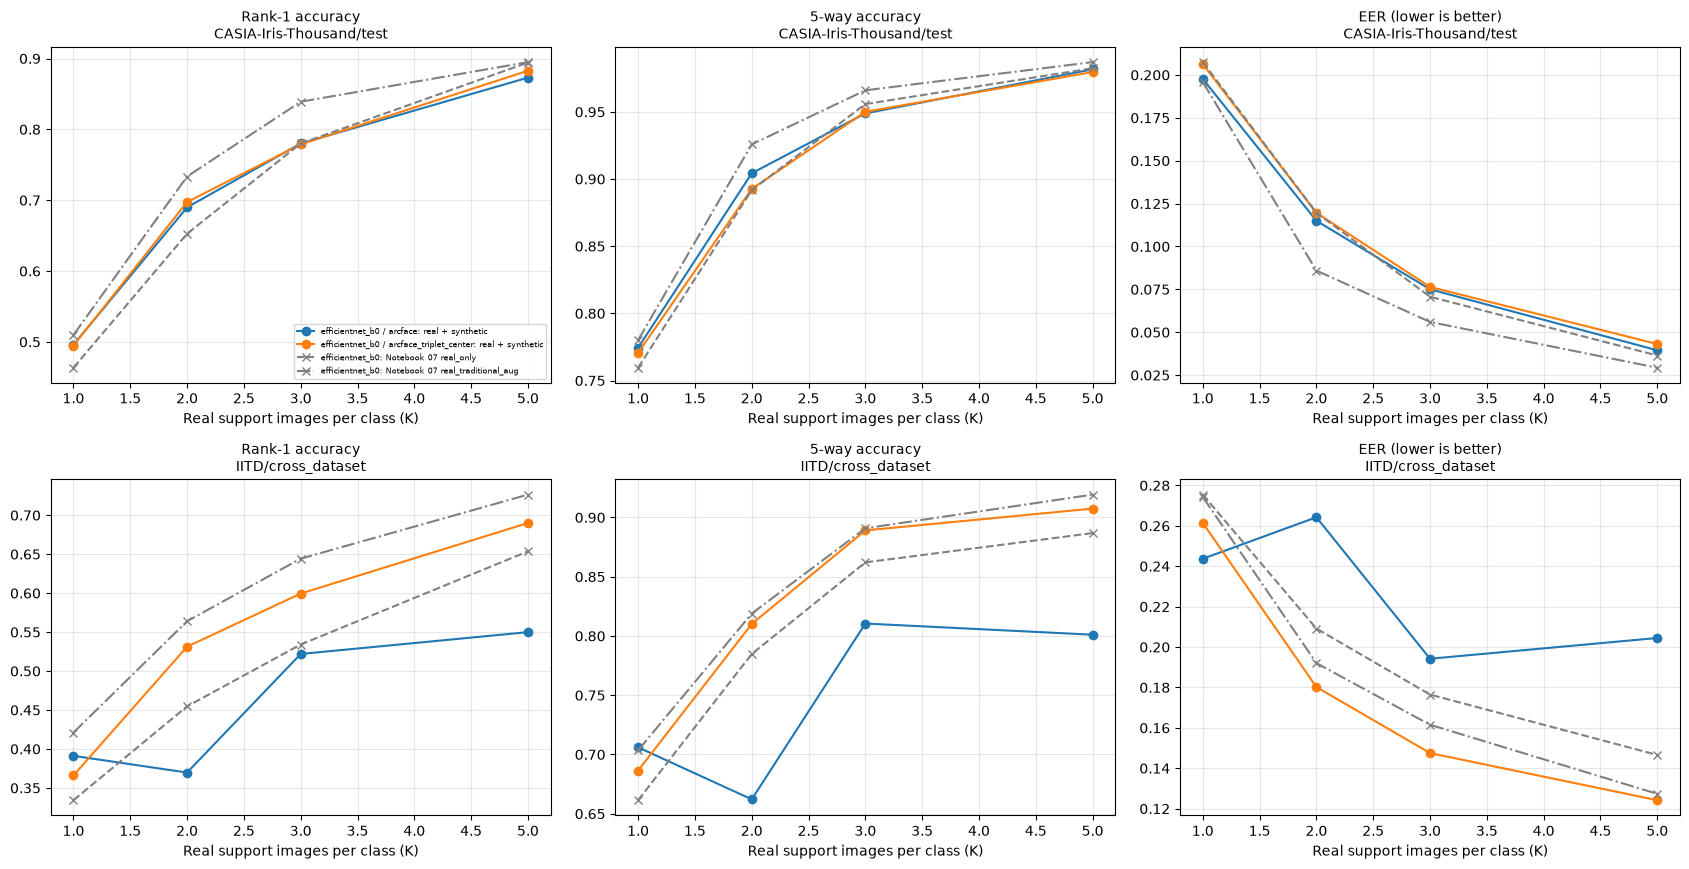

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_metrics_vs_shots.png


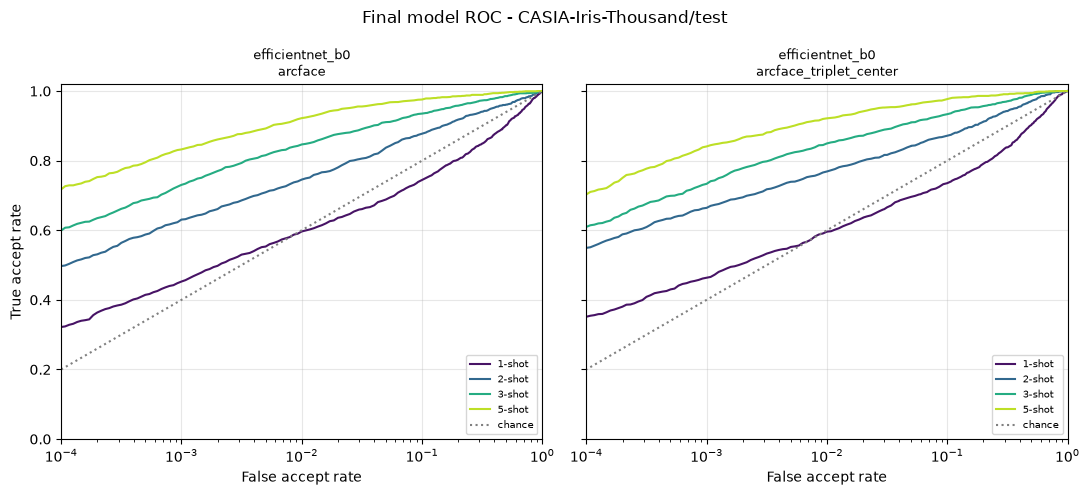

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_roc_CASIA-Iris-Thousand__test.png


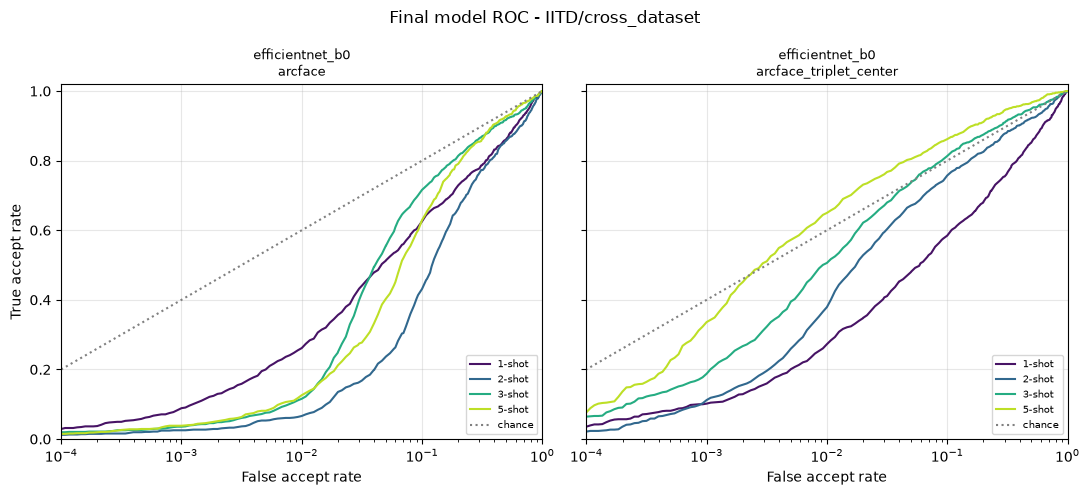

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_roc_IITD__cross_dataset.png


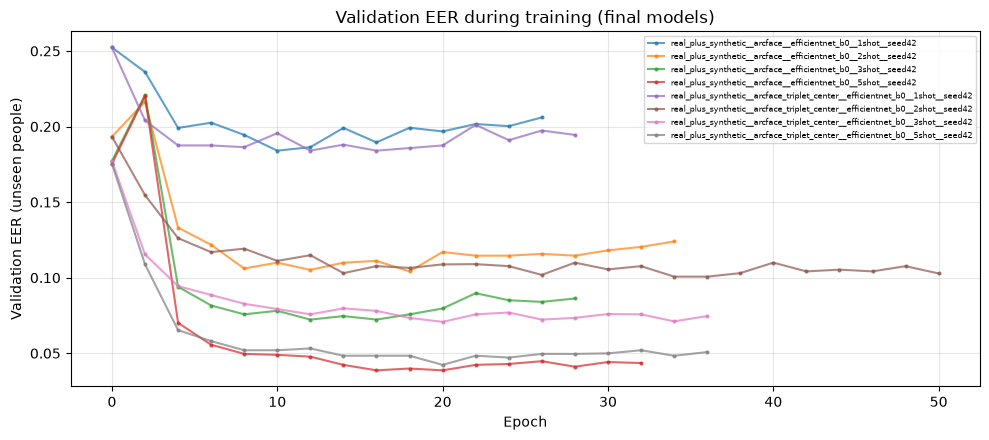

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_validation_curves.png


In [21]:
# ============================================================
# 18. Plots
# ============================================================

headline_sets = sorted(summary.loc[summary["kind"].isin(["within_dataset_test", "cross_dataset"]), "eval_set"].unique())
panels = [("rank1_acc_mean", "Rank-1 accuracy"), ("acc_5way_mean", f"{EPISODE_WAY}-way accuracy"), ("eer_mean", "EER (lower is better)")]
palette = plt.cm.tab10(np.arange(10))
configurations = sorted(set(zip(final["backbone"], final["loss_variant"])))
color_of = {config: palette[i % 10] for i, config in enumerate(configurations)}

baseline_available = BASELINE_SUMMARY_PATH.exists()
baseline_table = pd.read_csv(BASELINE_SUMMARY_PATH) if baseline_available else None

fig, axes = plt.subplots(len(headline_sets), 3, figsize=(17, 4.4 * len(headline_sets)), squeeze=False)

for row, eval_set in enumerate(headline_sets):
    for col, (column, title) in enumerate(panels):
        ax = axes[row, col]

        for (backbone, loss_variant) in configurations:
            color = color_of[(backbone, loss_variant)]
            for data_variant, style, label in [("real_plus_synthetic", "-", "real + synthetic"), ("real_only", ":", "same-code real only")]:
                line = summary[(summary["eval_set"] == eval_set) & (summary["backbone"] == backbone)
                               & (summary["loss_variant"] == loss_variant) & (summary["data_variant"] == data_variant)].sort_values("shot")
                if len(line):
                    ax.plot(line["shot"], line[column], style, marker="o", color=color, label=f"{backbone} / {loss_variant}: {label}")

        if baseline_available:
            for backbone in sorted({b for b, _ in configurations}):
                for variant, style in [("real_only", "--"), ("real_traditional_aug", "-.")]:
                    line = baseline_table[(baseline_table["eval_set"] == eval_set) & (baseline_table["backbone"] == backbone)
                                          & (baseline_table["variant"] == variant)].sort_values("shot")
                    if len(line):
                        ax.plot(line["shot"], line[column], style, marker="x", color="gray", label=f"{backbone}: Notebook 07 {variant}")

        ax.set_xlabel("Real support images per class (K)")
        ax.set_title(f"{title}\n{eval_set}", fontsize=10)
        ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=6)
plt.tight_layout()
shots_plot_path = RESULTS_DIR / "final_metrics_vs_shots.png"
plt.savefig(shots_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", shots_plot_path)

# ---- ROC curves of the final models ----
roc_final = roc_points[roc_points["data_variant"] == "real_plus_synthetic"]
roc_mean = roc_final.groupby(["backbone", "loss_variant", "shot", "eval_set", "fpr"], as_index=False)["tpr"].mean()
shots_present = sorted(roc_mean["shot"].unique())
shot_colors = dict(zip(shots_present, plt.cm.viridis(np.linspace(0.05, 0.9, max(len(shots_present), 1)))))

for eval_set in headline_sets:
    fig, axes = plt.subplots(1, len(configurations), figsize=(5.5 * len(configurations), 5), sharey=True, squeeze=False)
    for ax, (backbone, loss_variant) in zip(axes[0], configurations):
        for shot in shots_present:
            curve = roc_mean[(roc_mean["eval_set"] == eval_set) & (roc_mean["backbone"] == backbone)
                             & (roc_mean["loss_variant"] == loss_variant) & (roc_mean["shot"] == shot) & (roc_mean["fpr"] > 0)]
            if len(curve):
                ax.plot(curve["fpr"], curve["tpr"], color=shot_colors[shot], label=f"{shot}-shot")
        ax.plot([1e-5, 1], [1e-5, 1], ":", color="gray", label="chance")
        ax.set_xscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(0, 1.02)
        ax.set_title(f"{backbone}\n{loss_variant}", fontsize=9)
        ax.set_xlabel("False accept rate")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc="lower right")
    axes[0, 0].set_ylabel("True accept rate")
    plt.suptitle(f"Final model ROC - {eval_set}", fontsize=12)
    plt.tight_layout()
    roc_path = RESULTS_DIR / f"final_roc_{safe_name(eval_set)}.png"
    plt.savefig(roc_path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", roc_path)

# ---- validation EER over the epochs ----
fig, ax = plt.subplots(figsize=(10, 4.5))
for run_id, group in history[history["data_variant"] == "real_plus_synthetic"].groupby("run_id"):
    validated = group.dropna(subset=["val_eer"]).sort_values("epoch")
    if len(validated):
        ax.plot(validated["epoch"], validated["val_eer"], marker="o", markersize=2, alpha=0.7, label=run_id)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation EER (unseen people)")
ax.set_title("Validation EER during training (final models)")
ax.grid(alpha=0.3)
if history["run_id"].nunique() <= 10:
    ax.legend(fontsize=6)
plt.tight_layout()
curves_path = RESULTS_DIR / "final_validation_curves.png"
plt.savefig(curves_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", curves_path)

## 19. Sanity checks

**Stop the notebook if:**
- a planned run is missing or failed its leakage assertions;
- a `real_plus_synthetic` run did not use any synthetic image;
- a saved checkpoint cannot be loaded and run;
- a best-model file is missing, or the best model is not the one with the lowest validation EER.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- the training loss did not fall, or ImageNet weights were not loaded;
- test Rank-1 is not above twice chance;
- the final model is **not** better than a reference on the test identities (**this is a result, not an error**: report it honestly).

In [22]:
# ============================================================
# 19. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


def load_final_model(path):
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location="cpu")

    model = EmbeddingNet(checkpoint["backbone"], checkpoint["embedding_dim"], pretrained=False, square_size=checkpoint["vit_input_size"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval(), checkpoint


expected_ids = {make_run_id(*row) for row in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the train/evaluation leakage assertions", bool(runs_table["leakage_checks_passed"].all()))

synthetic_runs = runs_table[runs_table["data_variant"] == "real_plus_synthetic"]
add_check("every real_plus_synthetic run used synthetic images", bool((synthetic_runs["n_synthetic_images"] > 0).all()),
          f"{int((synthetic_runs['n_synthetic_images'] == 0).sum())} run(s) with none")

if SAVE_CHECKPOINTS:
    broken = []
    for _, run in runs_table.iterrows():
        try:
            model, checkpoint = load_final_model(CHECKPOINT_DIR / f"{run['run_id']}.pt")
            with torch.no_grad():
                out = model(torch.rand(2, 1, *INPUT_HW, device=DEVICE))
            ok = tuple(out.shape) == (2, checkpoint["embedding_dim"]) and bool(torch.isfinite(out).all())
        except Exception as error:
            ok = False
        if not ok:
            broken.append(run["run_id"])
    add_check("every saved checkpoint loads and produces finite embeddings", not broken, f"{len(broken)} broken")

if len(best_models):
    add_check("every best-model file exists", bool(best_models["copied"].all()), f"{int((~best_models['copied']).sum())} missing")

    rule_ok = True
    for _, row in best_models.iterrows():
        pool = candidates[candidates["shot"] == row["shot"]]
        rule_ok = rule_ok and row["val_eer"] <= pool.groupby(["backbone", "loss_variant"])["eer"].mean().min() + 1e-12
    add_check("the best model has the lowest validation EER among its shot's candidates", rule_ok)
else:
    add_check("a best model was selected", False, "no validation results", critical=False)

not_decreasing = runs_table[runs_table["final_loss"] >= runs_table["initial_loss"]]
add_check("training loss decreased in every run", len(not_decreasing) == 0, f"{len(not_decreasing)} run(s) did not improve", critical=False)
add_check("ImageNet weights were loaded in every run", bool(runs_table["pretrained_loaded"].all()) or not USE_PRETRAINED,
          f"{int((~runs_table['pretrained_loaded']).sum())} run(s) used random initialisation", critical=False)

test_rows = results[results["kind"] == "within_dataset_test"]
near_chance = test_rows[test_rows["rank1_acc"] <= 2 * test_rows["chance_rank1"]]
add_check("test Rank-1 is more than twice chance everywhere", len(near_chance) == 0,
          f"{len(near_chance)} of {len(test_rows)} results are near chance", critical=False)

if len(comparison):
    test_comparison = comparison[comparison["kind"] == "within_dataset_test"]
    for reference, group in test_comparison.groupby("reference"):
        worse = group[group["eer_change"] >= 0]
        add_check(f"final models have a lower test EER than {reference} (a result, not an error)", len(worse) == 0,
                  f"{len(worse)} of {len(group)} comparisons are not better", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "final_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "final_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical final-model checks failed: {failed_names}"
print("\nFinal-model sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the train/evaluation leakage assertions
[PASS] every real_plus_synthetic run used synthetic images  (0 run(s) with none)
[PASS] every saved checkpoint loads and produces finite embeddings  (0 broken)
[PASS] every best-model file exists  (0 missing)
[PASS] the best model has the lowest validation EER among its shot's candidates
[PASS] training loss decreased in every run  (0 run(s) did not improve)
[PASS] ImageNet weights were loaded in every run  (0 run(s) used random initialisation)
[PASS] test Rank-1 is more than twice chance everywhere  (0 of 8 results are near chance)
[WARN] final models have a lower test EER than nb07_real_only (a result, not an error)  (4 of 8 comparisons are not better)
[WARN] final models have a lower test EER than nb07_real_traditional_aug (a result, not an error)  (8 of 8 comparisons are not better)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition\final_

## 20. Final outputs

At the end of Notebook 13, the project should contain:

```text
checkpoints/final_recognition/
├── <data>__<loss>__<backbone>__<K>shot__seed<S>.pt     every trained model (best-validation weights)
└── best/best_<K>shot.pt                                the BEST recognition model per shot

results/final_recognition/
├── best_recognition_models.csv, best_model_card.json   which model is best, and why
├── final_accuracy.csv, final_roc.csv, final_eer.csv    the metrics (same columns as Notebook 07)
├── final_results.csv, final_summary.csv, final_runs.csv, final_training_history.csv
├── comparison_with_baselines.csv                       against Notebook 07 and the same-code control
├── final_sanity_checks.csv
├── runs/                                               one JSON record per training run
└── final_metrics_vs_shots.png, final_roc_<evaluation set>.png, final_validation_curves.png
```

In [23]:
# ============================================================
# 20. Final output listing
# ============================================================

print("Notebook 13 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nRun records: {len(list(RUNS_DIR.glob('*.json')))} | checkpoints: {len(list(CHECKPOINT_DIR.glob('*.pt')))} | "
      f"best models: {len(list(BEST_DIR.glob('*.pt')))}")
print("\nNotebook 13 completed.")

Notebook 13 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\final_recognition

Top-level generated files:
- best_model_card.json
- best_recognition_models.csv
- comparison_with_baselines.csv
- final_accuracy.csv
- final_eer.csv
- final_metrics_vs_shots.png
- final_results.csv
- final_roc.csv
- final_roc_CASIA-Iris-Thousand__test.png
- final_roc_IITD__cross_dataset.png
- final_runs.csv
- final_sanity_checks.csv
- final_summary.csv
- final_training_history.csv
- final_validation_curves.png

Run records: 8 | checkpoints: 8 | best models: 4

Notebook 13 completed.


## 21. What this notebook hands to the rest of the project

```text
Notebooks 07 and 11                 Notebook 13                            Notebooks 14 - 18
Baselines, accepted       --->     Final recognition model:        --->   14: cross-dataset evaluation
synthetic images                   real + synthetic, ArcFace +            15: explainability
                                   Triplet + Center                       16: ablations   17-18: tables, statistics
```

### How the outputs are used

| Notebook | Use |
|---|---|
| **14 Cross-dataset evaluation** | The `<other dataset>/cross_dataset` rows of `final_*.csv` already give the CASIA-to-IITD result of every final model; Notebook 14 can load `best/best_<K>shot.pt` for the full measure set (Rank-1, verification accuracy, EER, TAR@FAR) |
| **15 Explainability** | Load `best/best_<K>shot.pt` (and the matching Notebook 07 checkpoint) and compare attention and embedding clusters |
| **16 Ablations** | Re-run this notebook with: `SYNTHETIC_PER_IDENTITY` in {5, 10, 20, 50} (nested subsets by the synthetic index); `LOSS_VARIANTS`; other `BACKBONES`; another quality threshold (Notebook 11's `TARGET_FAR`); `"real_only"` in `DATA_VARIANTS` for the control; `TRADITIONAL_AUG` |
| **17 Performance comparison** | `final_accuracy.csv`, `final_eer.csv`, `final_roc.csv` have the same columns as the baseline files; the `data_variant` and `loss_variant` columns say which row is which |
| **18 Statistical significance** | Use several `SEEDS` (the files keep every seed); the per-seed values are in `final_results.csv` |

### Loading a trained model

```python
model, checkpoint = load_final_model(BEST_DIR / "best_3shot.pt")      # defined in section 19
embeddings = extract_embeddings(model, images_uint8)                 # unit-length, [N, 256]
```

### Rules that keep the no-leakage guarantee intact

1. Synthetic images are used for **training only**, and only those of training identities. Validation, test, and the unseen dataset stay real.
2. The best model is selected with the **validation** identities only. Do not choose a backbone, loss variant, or threshold by looking at test or cross-dataset results.
3. Use the synthetic images of the **same shot** as the experiment.
4. Report `CONFIG_HASH`, the seed, `SYNTHETIC_SOURCE`, and `SYNTHETIC_PER_IDENTITY` with every number.
5. A claim that synthetic data helps must be made against the **traditional-augmentation baseline** as well, not only against real-only training.

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| Final model no better than the baseline | The synthetic images add little identity information | Check Notebooks 11 and 12 (acceptance rate, diversity); raise or lower `FINAL_REAL_FRACTION`; try `SYNTHETIC_PER_IDENTITY` |
| Better than Notebook 07 but not than the same-code control | The gain comes from the sampler / loss, not from synthetic data | Report the control, not Notebook 07, as the reference for the synthetic-data claim |
| Test EER worse with the full loss than with `arcface` | Triplet / center weights too large or too small | Tune `W_TRIPLET`, `W_CENTER` on the **validation** EER |
| Large gap between validation and test | Few validation identities, noisy selection | Use more seeds; check the number of validation identities in Notebook 06 |
| Training accuracy near 100% but validation EER no better | The model memorises the real images | Lower `FINAL_REAL_FRACTION`, add `TRADITIONAL_AUG`, stop earlier |
| Training loss stuck high at the start | ArcFace margin 0.5 with random weights | Check that the pretrained weights were loaded (`pretrained_loaded`) |